In [ ]:
#ASSESSMENT - 1
Dataframe Operations & Data Transformations

We create three data frames of product details and locations, then combine them using append, 
concatenation, merge, and the four joins (inner, left, right, full outer), which differ in which
unmatched rows they keep. Next, we make a vector of 10 numbers starting with the last four digits
of the registration number, and transform it using normalization (fixed ranges like 0 to 1), 
Z-score (distance from the average), and decimal scaling (dividing by powers of 10 until all 
values are below 1).

In [1]:

import pandas as pd
import numpy as np

# Create data frames
dataframe1 = pd.DataFrame({
    "ProductID":  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "NameofProd": ["Laptop", "Mouse", "Keyboard", "Monitor", "Printer",
                   "Scanner", "Webcam", "Headset", "Router", "Tablet"],
    "Price":      [55000, 500, 1200, 9500, 7200, 6400, 2100, 1800, 2500, 22000]
})

dataframe2 = pd.DataFrame({
    "ProductID":        [3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "Company_Location": ["Chennai", "Mumbai", "Delhi", "Pune", "Bengaluru",
                         "Hyderabad", "Kolkata", "Coimbatore", "Jaipur", "Kochi"]
})

dataframe3 = pd.DataFrame({
    "ProductID":  [11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
    "NameofProd": ["Pen Drive", "Hard Disk", "SSD", "Speaker", "Projector",
                   "UPS", "Charger", "Power Bank", "Smart Watch", "Microphone"],
    "Price":      [600, 4200, 5200, 3000, 32000, 4800, 900, 1500, 8500, 2700]
})

print("dataframe1:\n", dataframe1, "\n")
print("dataframe2:\n", dataframe2, "\n")
print("dataframe3:\n", dataframe3, "\n")

# Append dataframe1 and dataframe3
appended_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print("Appended:\n", appended_df, "\n")

# Concatenate row-wise and column-wise
row_concat = pd.concat([dataframe1, dataframe3], axis=0, ignore_index=True)
col_concat = pd.concat([dataframe1.set_index("ProductID"),
                        dataframe2.set_index("ProductID")], axis=1).reset_index()
print("Row-wise concatenation:\n", row_concat, "\n")
print("Column-wise concatenation:\n", col_concat, "\n")

# Merge dataframe1 and dataframe2
merged_df = pd.merge(dataframe1, dataframe2, on="ProductID")
print("Merge:\n", merged_df, "\n")

# Join operations
inner_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="inner")
left_join  = pd.merge(dataframe1, dataframe2, on="ProductID", how="left")
right_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="right")
outer_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="outer")

print("Inner Join:\n", inner_join, "\n")
print("Left Join:\n", left_join, "\n")
print("Right Join:\n", right_join, "\n")
print("Full Outer Join:\n", outer_join, "\n")

# Create numeric vector (rename Fname to your first name)
Fname = pd.Series([4521, 12, 45, 78, 23, 90, 56, 34, 67, 81], dtype=float)
print("Original vector:\n", Fname.values, "\n")

# Normalization to given ranges
def scale_range(x, a, b):
    return a + (x - x.min()) * (b - a) / (x.max() - x.min())

norm_minus3_plus3 = scale_range(Fname, -3, 3)
norm_minus1_plus1 = scale_range(Fname, -1, 1)
norm_0_1          = scale_range(Fname, 0, 1)

# Z-score transformation
z_score = (Fname - Fname.mean()) / Fname.std(ddof=0)

# Decimal scaling normalization
j = len(str(int(Fname.abs().max())))
decimal_scaled = Fname / (10 ** j)

result = pd.DataFrame({
    "Original":        Fname,
    "Norm [-3, +3]":   norm_minus3_plus3.round(4),
    "Norm [-1, +1]":   norm_minus1_plus1.round(4),
    "MinMax [0, 1]":   norm_0_1.round(4),
    "Z-score":         z_score.round(4),
    "Decimal Scaling": decimal_scaled.round(4)
})
print("Transformation results:\n", result)
print(f"\nDecimal scaling used j = {j} (divisor = {10**j})")

dataframe1:
    ProductID NameofProd  Price
0          1     Laptop  55000
1          2      Mouse    500
2          3   Keyboard   1200
3          4    Monitor   9500
4          5    Printer   7200
5          6    Scanner   6400
6          7     Webcam   2100
7          8    Headset   1800
8          9     Router   2500
9         10     Tablet  22000 

dataframe2:
    ProductID Company_Location
0          3          Chennai
1          4           Mumbai
2          5            Delhi
3          6             Pune
4          7        Bengaluru
5          8        Hyderabad
6          9          Kolkata
7         10       Coimbatore
8         11           Jaipur
9         12            Kochi 

dataframe3:
    ProductID   NameofProd  Price
0         11    Pen Drive    600
1         12    Hard Disk   4200
2         13          SSD   5200
3         14      Speaker   3000
4         15    Projector  32000
5         16          UPS   4800
6         17      Charger    900
7         18   Power B

In [ ]:
#ASSESSMENT - 2

Data Import, Transform and Basic Statistical Analysis

We import the lithium-ion battery dataset and explore it by viewing the first and last 10
records, its size, column names, data types and summary statistics. Then we find and handle
missing values (removing rows, filling with mean, median, mode, forward/backward fill, or a 
constant), remove duplicates, convert columns to factors, rename a column and create a new 
derived column. Finally, we calculate the minimum, maximum, range, variance, standard deviation
and IQR of a numerical variable.

In [2]:
import pandas as pd
import numpy as np

# 1. Import the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url, na_values=["", "NA", "N/A"])
# If you downloaded the file from email, use: df = pd.read_csv("yourfile.csv")

# 2. First 10 records
print("First 10 records:\n", df.head(10), "\n")

# 3. Last 10 records
print("Last 10 records:\n", df.tail(10), "\n")

# 4. Total rows and columns
print("Rows:", df.shape[0], " Columns:", df.shape[1], "\n")

# 5. Names of all variables
print("Columns:", list(df.columns), "\n")

# 6. Data type of each variable
print("Data types:\n", df.dtypes, "\n")
df.info()

# 7. Summary statistics
print("\nSummary statistics:\n", df.describe(include="all"), "\n")

# 8 & 10. Missing values in each column
print("Missing values per column:\n", df.isnull().sum(), "\n")

# 9. Total missing values
print("Total missing values:", df.isnull().sum().sum(), "\n")

# 11. Rows with at least one missing value
rows_with_na = df[df.isnull().any(axis=1)]
print("Rows with missing values:", len(rows_with_na))
print(rows_with_na.head(10), "\n")

# 12. Remove rows with missing values
df_clean = df.dropna()
print("Rows after removal:", len(df_clean))
print(df_clean.head(10), "\n")

# Pick columns automatically (change these names if you want specific columns)
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
num1 = num_cols[0]
num2 = num_cols[1] if len(num_cols) > 1 else num_cols[0]
cat1 = cat_cols[0]
print("Numeric columns used:", num1, "and", num2, "| Categorical column used:", cat1, "\n")

# 13. Replace missing values with mean
df_mean = df.copy()
df_mean[num1] = df_mean[num1].fillna(df_mean[num1].mean())
print("Missing in", num1, "after mean fill:", df_mean[num1].isnull().sum())

# 14. Replace missing values with median
df_median = df.copy()
df_median[num2] = df_median[num2].fillna(df_median[num2].median())
print("Missing in", num2, "after median fill:", df_median[num2].isnull().sum())

# 15. Replace missing values in categorical column with mode
df_mode = df.copy()
df_mode[cat1] = df_mode[cat1].fillna(df_mode[cat1].mode()[0])
print("Missing in", cat1, "after mode fill:", df_mode[cat1].isnull().sum(), "\n")

# 16. Forward filling
df_ffill = df.ffill()
print("Forward fill:\n", df_ffill.head(10), "\n")

# 17. Backward filling
df_bfill = df.bfill()
print("Backward fill:\n", df_bfill.head(10), "\n")

# 18. Replace remaining missing values with a constant (0 for numeric, "Unknown" for text)
df_const = df.copy()
df_const[num_cols] = df_const[num_cols].fillna(0)
df_const[cat_cols] = df_const[cat_cols].fillna("Unknown")
print("Missing after constant fill:", df_const.isnull().sum().sum(), "\n")

# Working dataset for the next steps
df2 = df_const.copy()

# 19. Remove duplicate records
print("Duplicates found:", df2.duplicated().sum())
df2 = df2.drop_duplicates()
print("Rows after removing duplicates:", len(df2), "\n")

# 20. Convert appropriate variables into factors (category)
df2[cat1] = df2[cat1].astype("category")
print(df2.dtypes, "\n")

# 21. Rename column names
df2 = df2.rename(columns={num1: num1 + "_New"})
num1 = num1 + "_New"
print("Columns:", list(df2.columns), "\n")

# 22. Create a new derived column
df2["Derived_Col"] = df2[num1] * 2
print(df2.head(10), "\n")

# 23. Summary statistics
print("Summary statistics:\n", df2.describe(), "\n")

# 24. Minimum and maximum
print("Minimum:", df2[num1].min(), " Maximum:", df2[num1].max())

# 25. Range
print("Range:", df2[num1].max() - df2[num1].min())

# 26. Variance
print("Variance:", df2[num1].var())

# 27. Standard deviation
print("Standard deviation:", df2[num1].std())

# 28. Interquartile range
print("IQR:", df2[num1].quantile(0.75) - df2[num1].quantile(0.25))

First 10 records:
   Materials Id       Formula Spacegroup  Formation Energy (eV)  \
0    mp-849394     Li2MnSiO4         Pc                 -2.699   
1    mp-783909     Li2MnSiO4      P21/c                 -2.696   
2    mp-761311    Li4MnSi2O7         Cc                 -2.775   
3    mp-761598  Li4Mn2Si3O10       C2/c                 -2.783   
4    mp-767709  Li2Mn3Si3O10       C2/c                 -2.747   
5    mp-761517    Li4MnSi2O7         C2                 -2.763   
6    mp-850949      LiMnSiO4        P21                 -2.650   
7    mp-853204     Li2MnSiO4      P21/c                 -2.676   
8    mp-767360   LiMn(SiO3)2       C2/c                 -2.822   
9    mp-764791  Li2Mn(SiO3)2         Cc                 -2.823   

  E Above Hull (eV)  Band Gap (eV)  Nsites  Density (gm/cc)   Volume  \
0             0.006          3.462      16            2.993  178.513   
1             0.008          2.879      32            2.926  365.272   
2             0.012          3.653    

In [ ]:
#Assessment 3

Data Cleaning and Univariate Analysis

We import the lithium-ion dataset and clean it by handling missing values, duplicates, data types 
and outliers, using pandas in place of dplyr/tidyr/forcats/stringr. Then we visualise it with 
matplotlib and seaborn in place of ggplot2: histogram, density, violin and dot plots for a 
numeric column, and frequency tables with bar, pie, lollipop and dot charts for a categorical 
column, ending with a faceted plot comparing the distribution across groups.

  Materials Id       Formula Spacegroup  Formation Energy (eV)  \
0    mp-849394     Li2MnSiO4         Pc                 -2.699   
1    mp-783909     Li2MnSiO4      P21/c                 -2.696   
2    mp-761311    Li4MnSi2O7         Cc                 -2.775   
3    mp-761598  Li4Mn2Si3O10       C2/c                 -2.783   
4    mp-767709  Li2Mn3Si3O10       C2/c                 -2.747   
5    mp-761517    Li4MnSi2O7         C2                 -2.763   

  E Above Hull (eV)  Band Gap (eV)  Nsites  Density (gm/cc)   Volume  \
0             0.006          3.462      16            2.993  178.513   
1             0.008          2.879      32            2.926  365.272   
2             0.012          3.653      28            2.761  301.775   
3             0.013          3.015      38            2.908  436.183   
4             0.016          2.578      36            3.334  421.286   
5             0.024          3.293      14            2.792  149.207   

   Has Bandstructure Crystal Sys

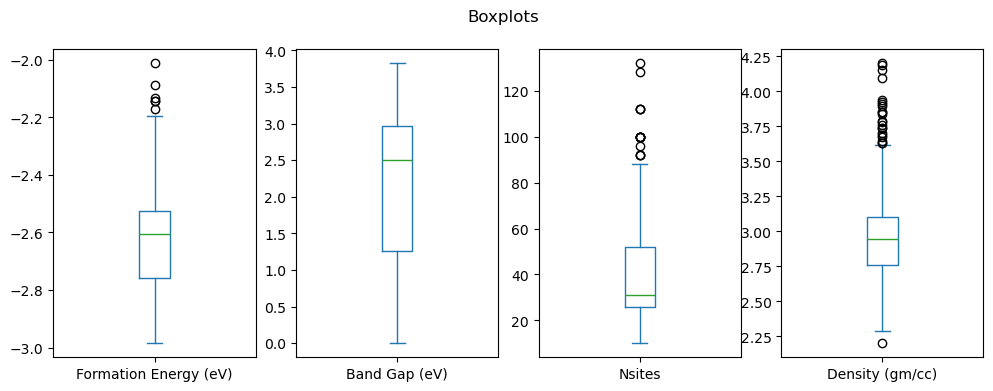

Outliers in Formation Energy (eV) : 6 

Rows after removing extreme outliers: 339 



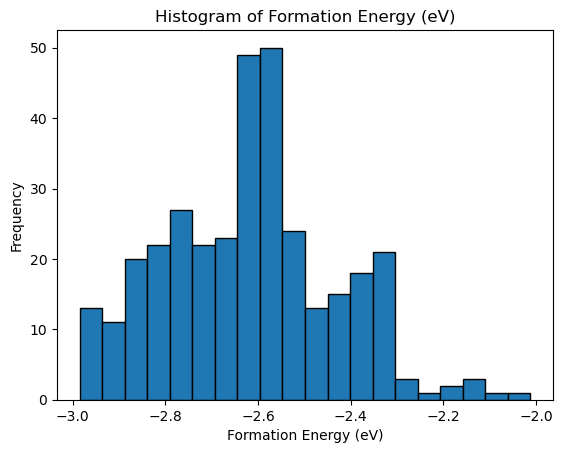

Skewness: 0.24 -> roughly symmetric 



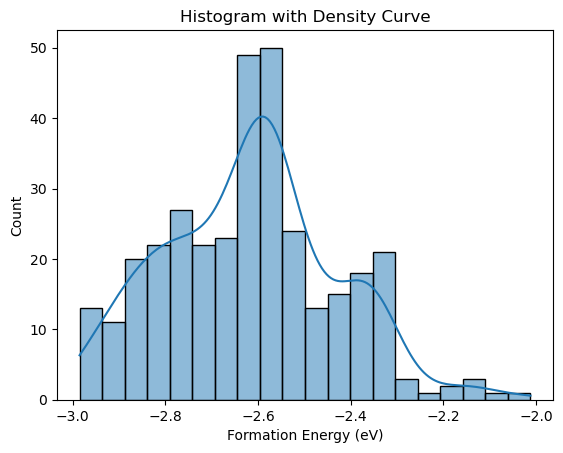

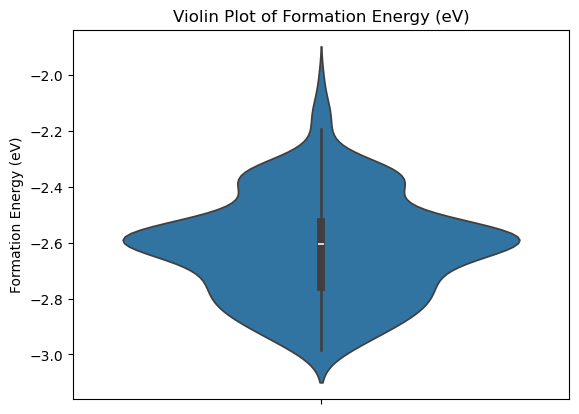

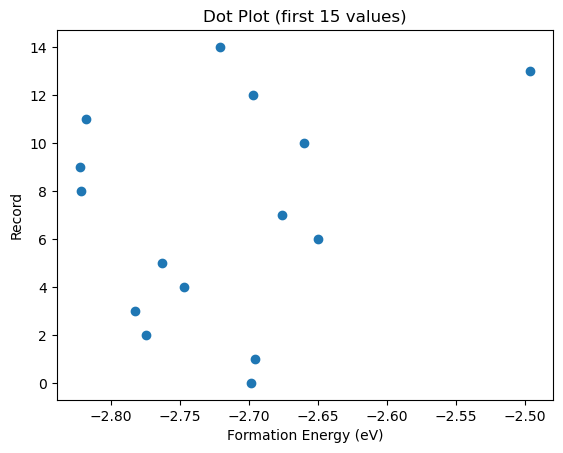

Frequency table:
 Spacegroup
p1       72
p21/c    32
pc       27
p21      23
cc       16
c2/c     15
c2       12
pna21    12
pcmn      8
p21nb     8
Name: count, dtype: int64 

            Count  Proportion  Percentage
Spacegroup                               
p1             72       0.212        21.2
p21/c          32       0.094         9.4
pc             27       0.080         8.0
p21            23       0.068         6.8
cc             16       0.047         4.7
c2/c           15       0.044         4.4
c2             12       0.035         3.5
pna21          12       0.035         3.5
pcmn            8       0.024         2.4
p21nb           8       0.024         2.4 



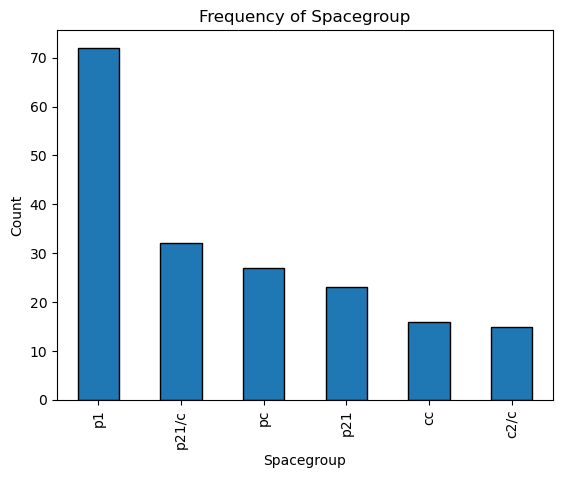

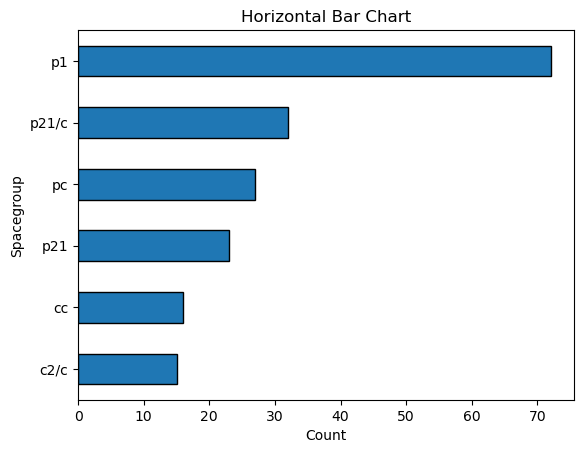

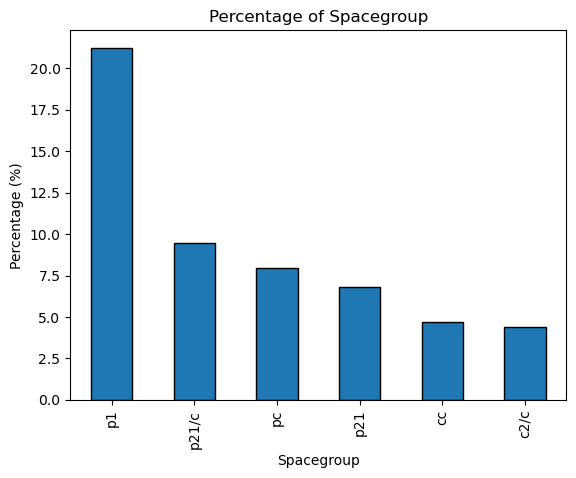

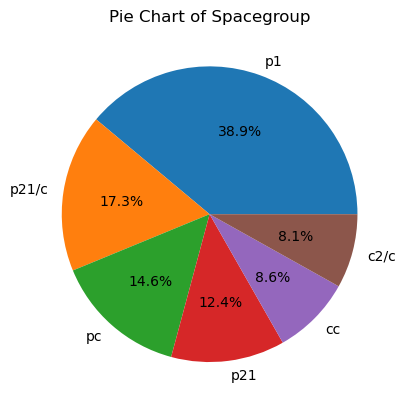

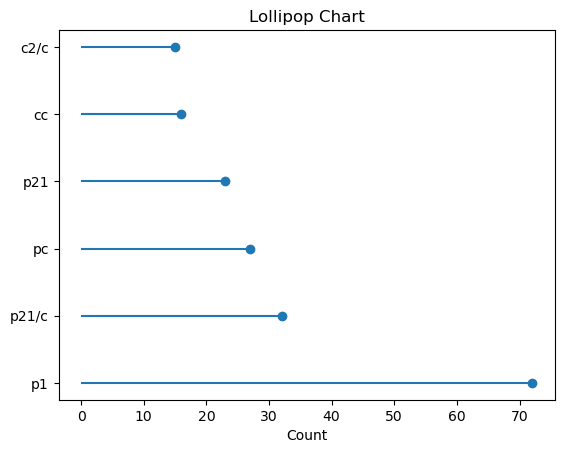

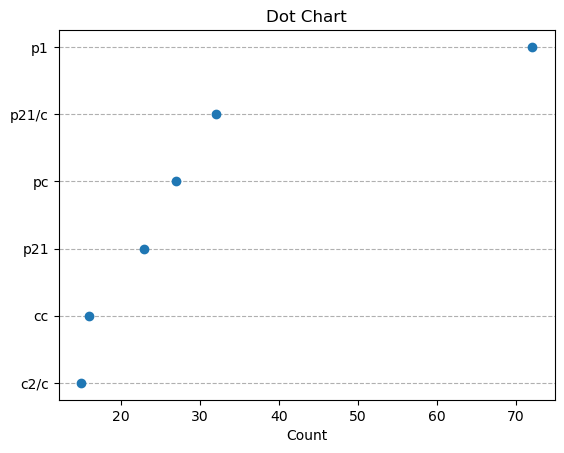

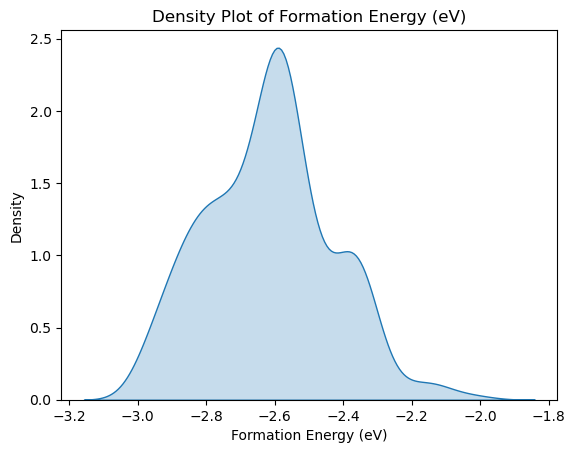

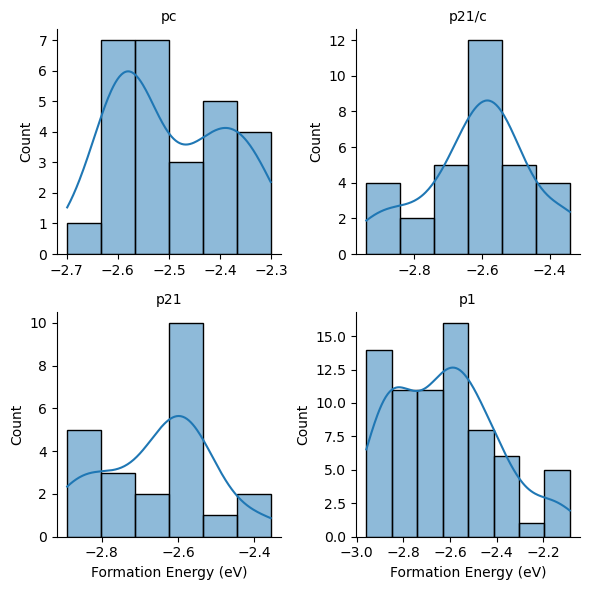

Skewness per group:
 Spacegroup
p1       0.49
p21     -0.08
p21/c   -0.32
pc       0.25
Name: Formation Energy (eV), dtype: float64


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Import the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url, na_values=["", "NA", "N/A"])
# If the link fails, download the CSV and use: df = pd.read_csv("lithium-ion batteries.csv")

# 2. First and last six records
print(df.head(6), "\n")
print(df.tail(6), "\n")

# 3. Total missing values
print("Total missing values:", df.isnull().sum().sum(), "\n")

# 4. Records with at least one missing value
print(df[df.isnull().any(axis=1)].head(10), "\n")

# 5. Remove columns with more than 70% missing values
df = df.loc[:, df.isnull().mean() <= 0.70]
print("Columns after removal:", list(df.columns), "\n")

# Column selection
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
num1 = "Formation Energy (eV)" if "Formation Energy (eV)" in df.columns else num_cols[0]
cat1 = "Spacegroup" if "Spacegroup" in df.columns else cat_cols[0]
print("Numeric column used:", num1, "| Categorical column used:", cat1, "\n")

# 6. Replace missing numerical values with the mean
df_mean = df.copy()
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())

# 7. Replace missing numerical values with the median
df_median = df.copy()
df_median[num_cols] = df_median[num_cols].fillna(df_median[num_cols].median())

# 8. Replace missing categorical values with the mode
for c in cat_cols:
    if df_median[c].notnull().any():
        df_median[c] = df_median[c].fillna(df_median[c].mode()[0])
df = df_median.copy()
print("Missing values left:", df.isnull().sum().sum(), "\n")

# 9. Identify duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 10. Remove duplicate rows
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df), "\n")

# 11. Identify columns with incorrect data types (text that looks numeric)
for c in df.select_dtypes(include="object").columns:
    if pd.to_numeric(df[c], errors="coerce").notnull().mean() > 0.9:
        print("Column", c, "is stored as text but looks numeric")
print(df.dtypes, "\n")

# 12. Convert character variables into factors (category)
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype("category")

# 13. Convert text values to lowercase
for c in df.select_dtypes(include="category").columns:
    df[c] = df[c].astype(str).str.lower().astype("category")
print(df.select_dtypes(include="category").head(), "\n")

# 14. Detect outliers using boxplots
cols = num_cols[:4]
df[cols].plot(kind="box", subplots=True, layout=(1, len(cols)), figsize=(12, 4))
plt.suptitle("Boxplots"); plt.show()

# 15. Identify outliers using the IQR method
Q1, Q3 = df[num1].quantile(0.25), df[num1].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df[num1] < Q1 - 1.5 * IQR) | (df[num1] > Q3 + 1.5 * IQR)]
print("Outliers in", num1, ":", len(outliers), "\n")

# 16. Remove extreme outliers (beyond 3 x IQR)
df = df[(df[num1] >= Q1 - 3 * IQR) & (df[num1] <= Q3 + 3 * IQR)]
print("Rows after removing extreme outliers:", len(df), "\n")

# 17. Histogram and interpretation
plt.hist(df[num1], bins=20, edgecolor="black")
plt.title("Histogram of " + num1); plt.xlabel(num1); plt.ylabel("Frequency"); plt.show()
skew = df[num1].skew()
print("Skewness:", round(skew, 2), "->",
      "right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "roughly symmetric", "\n")

# 18. Histogram with density curve
sns.histplot(df[num1], bins=20, kde=True)
plt.title("Histogram with Density Curve"); plt.show()

# 19. Violin plot
sns.violinplot(y=df[num1]); plt.title("Violin Plot of " + num1); plt.show()

# 20. Dot plot for a small numerical dataset
small = df[num1].head(15).reset_index(drop=True)
plt.plot(small, range(len(small)), "o")
plt.title("Dot Plot (first 15 values)"); plt.xlabel(num1); plt.ylabel("Record"); plt.show()

# 21. Frequency table
freq = df[cat1].astype(str).value_counts()
print("Frequency table:\n", freq.head(10), "\n")

# 22. Proportion and percentage
prop = freq / freq.sum()
print(pd.DataFrame({"Count": freq, "Proportion": prop.round(3),
                    "Percentage": (prop * 100).round(1)}).head(10), "\n")

top = freq.head(6)   # keep charts readable

# 23. Bar chart (frequency)
top.plot(kind="bar", edgecolor="black")
plt.title("Frequency of " + cat1); plt.ylabel("Count"); plt.show()

# 24. Horizontal bar chart
top.sort_values().plot(kind="barh", edgecolor="black")
plt.title("Horizontal Bar Chart"); plt.xlabel("Count"); plt.show()

# 25. Percentage bar chart
(prop.head(6) * 100).plot(kind="bar", edgecolor="black")
plt.title("Percentage of " + cat1); plt.ylabel("Percentage (%)"); plt.show()

# 26. Pie chart
top.plot(kind="pie", autopct="%1.1f%%", ylabel="")
plt.title("Pie Chart of " + cat1); plt.show()

# 27. Lollipop chart
plt.hlines(y=range(len(top)), xmin=0, xmax=top.values)
plt.plot(top.values, range(len(top)), "o")
plt.yticks(range(len(top)), top.index)
plt.title("Lollipop Chart"); plt.xlabel("Count"); plt.show()

# 28. Dot chart
t = top.sort_values()
plt.plot(t.values, t.index, "o"); plt.grid(axis="y", linestyle="--")
plt.title("Dot Chart"); plt.xlabel("Count"); plt.show()

# 29. Density plot
sns.kdeplot(df[num1], fill=True); plt.title("Density Plot of " + num1); plt.show()

# 30. Facet (distribution across groups)
groups = df[df[cat1].astype(str).isin(top.index[:4])].copy()
groups[cat1] = groups[cat1].astype(str)
g = sns.FacetGrid(groups, col=cat1, col_wrap=2, sharex=False, sharey=False)
g.map(sns.histplot, num1, kde=True)
g.set_titles("{col_name}"); plt.show()
print("Skewness per group:\n", groups.groupby(cat1)[num1].skew().round(2))

In [ ]:
#Lab Assessment 4

Bivariate Analysis Using R Programming

We load the lithium-ion dataset and use Crystal System and Has Bandstructure as the categorical 
variables, with Density, Formation Energy and Band Gap as the numerical ones. For the 
categorical pair we build a contingency table with stacked and grouped bar plots. For the 
numerical variables we draw a scatter plot, a line plot, a bar chart, a heatmap and a 
correlogram, and we compare Formation Energy across crystal systems with density, box, 
violin and combined violin-box plots. Every plot has a title, axis labels and a legend where 
needed

Numerical variables: ['Formation Energy (eV)', 'Band Gap (eV)', 'Nsites', 'Density (gm/cc)', 'Volume']
Categorical variables with few groups: ['Has Bandstructure', 'Crystal System'] 

Categories: Crystal System & Has Bandstructure | Numerics: Density (gm/cc) , Formation Energy (eV) , Band Gap (eV) 

Contingency table:
 Has Bandstructure  False  True
Crystal System                
?                      0     1
monoclinic            28   107
orthorhombic          22   106
triclinic             14    58 



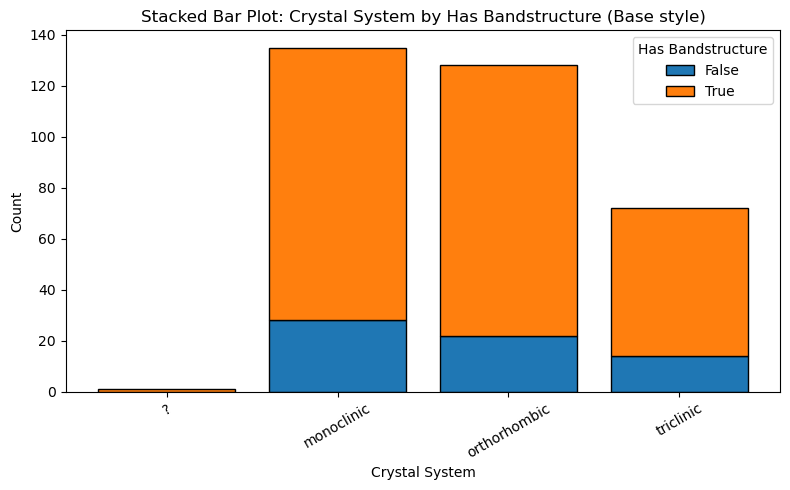

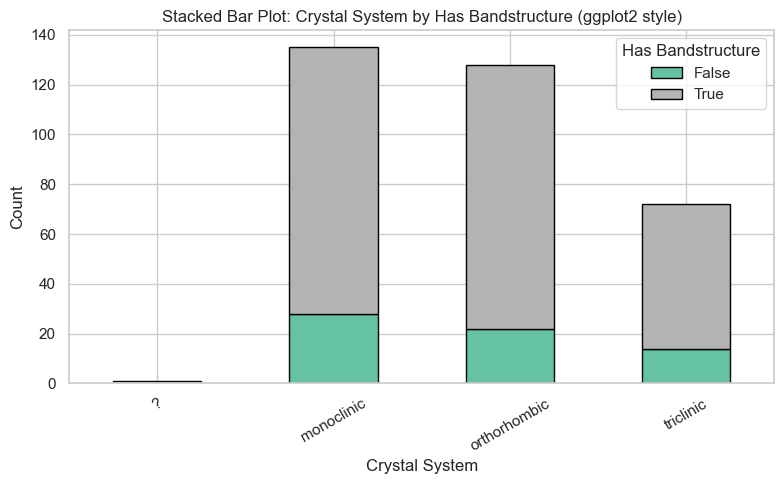

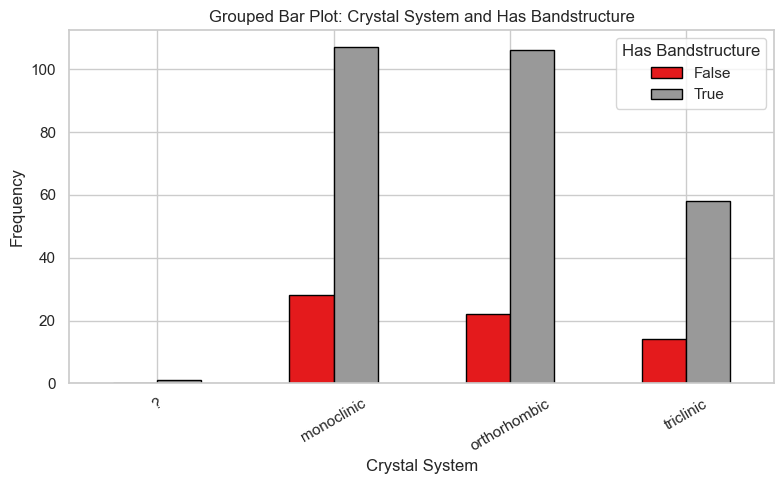

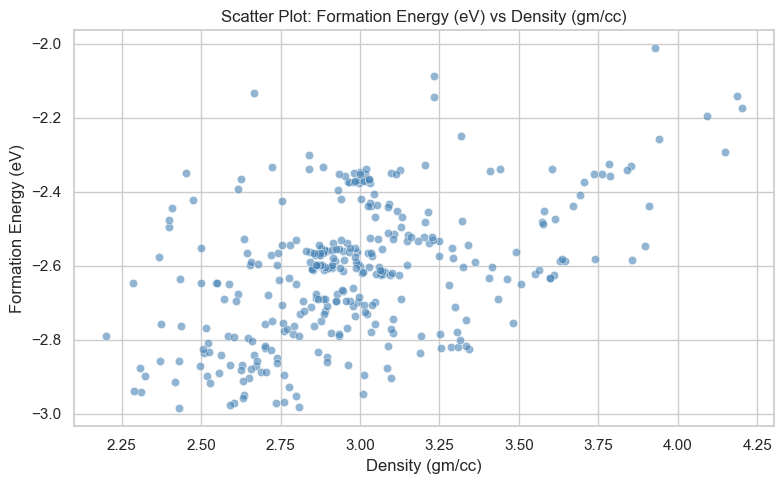

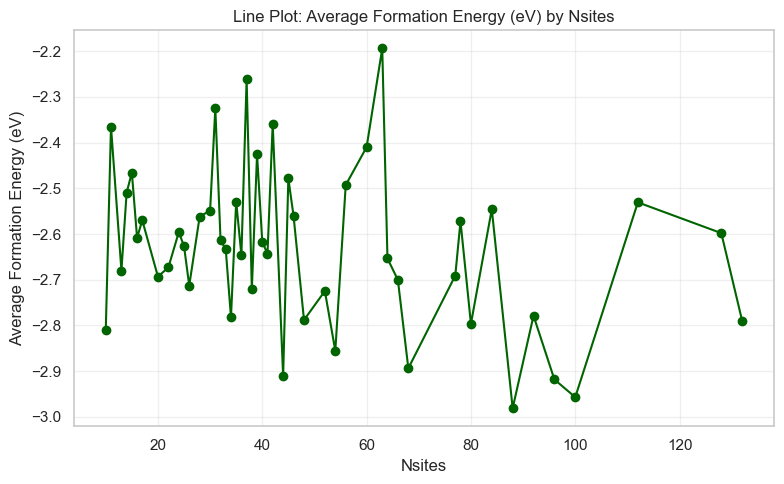

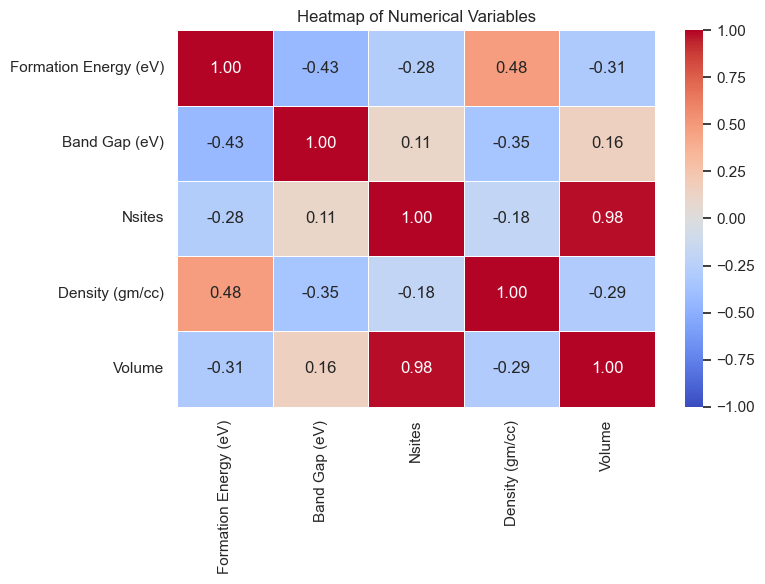

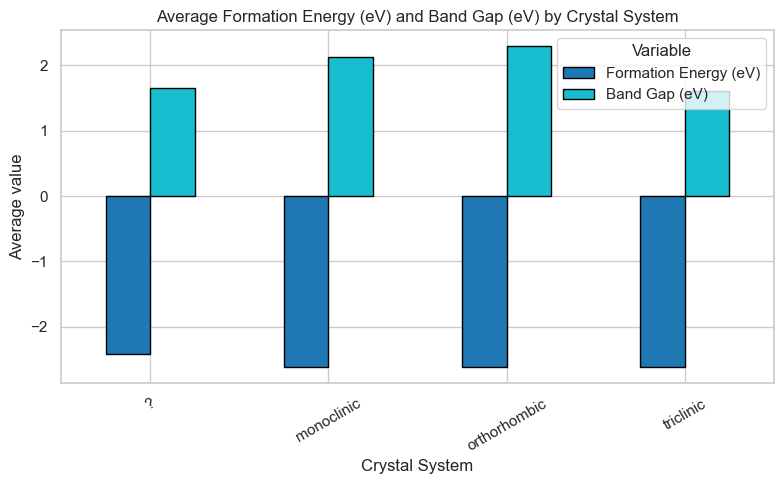

C:\Users\alekh\AppData\Local\Temp\ipykernel_15764\3337012671.py:91: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df, x=y, hue=cat1, fill=True, alpha=0.3, common_norm=False)


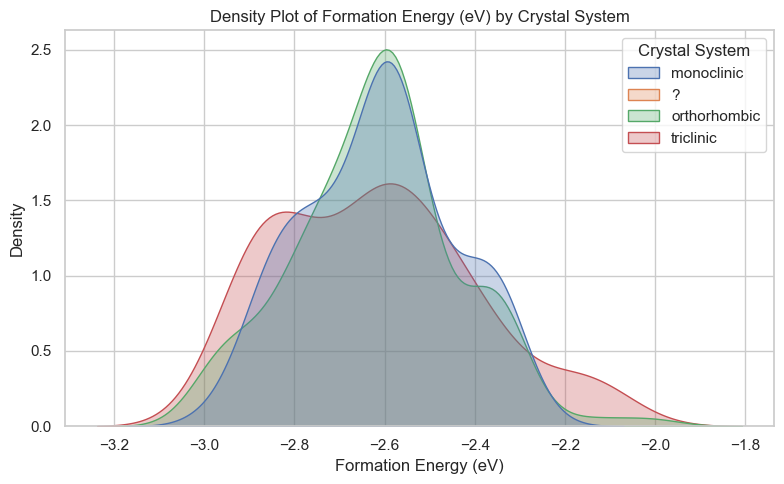

C:\Users\alekh\AppData\Local\Temp\ipykernel_15764\3337012671.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=cat1, y=y, palette="Set2")


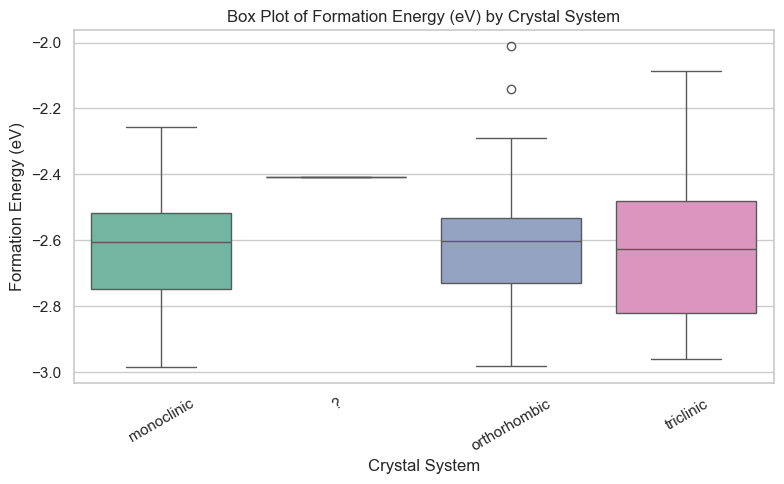

C:\Users\alekh\AppData\Local\Temp\ipykernel_15764\3337012671.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x=cat1, y=y, palette="Set3")


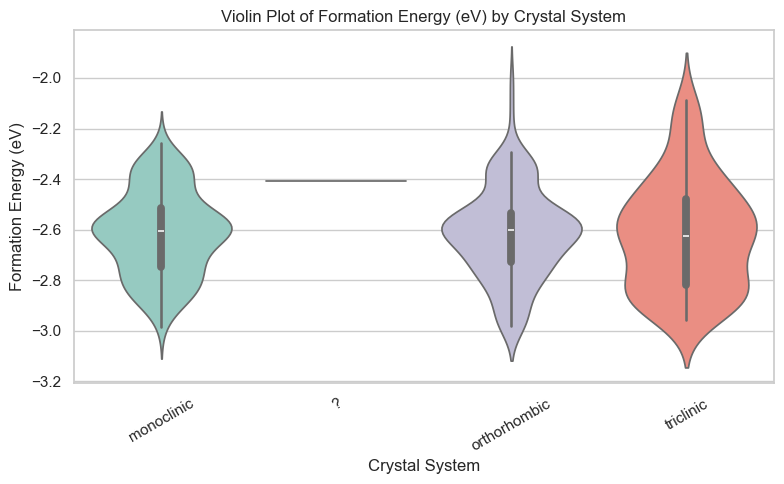

C:\Users\alekh\AppData\Local\Temp\ipykernel_15764\3337012671.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x=cat1, y=y, palette="pastel", inner=None)


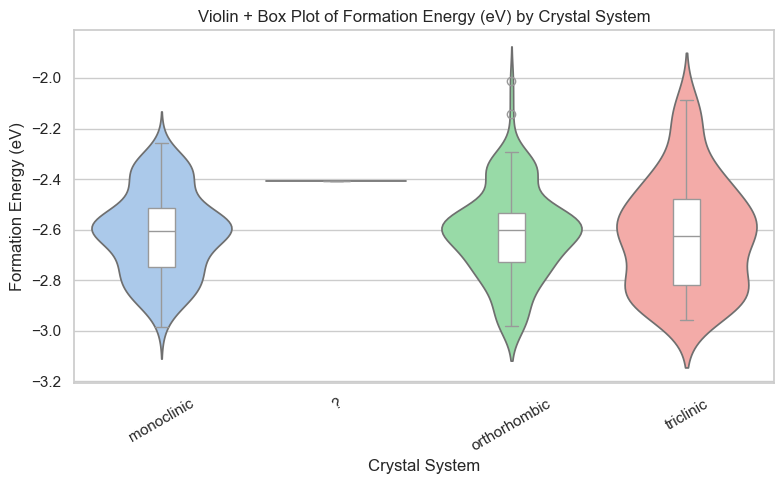

Correlation matrix:
                        Formation Energy (eV)  Band Gap (eV)  Nsites  \
Formation Energy (eV)                   1.00          -0.43   -0.28   
Band Gap (eV)                          -0.43           1.00    0.11   
Nsites                                 -0.28           0.11    1.00   
Density (gm/cc)                         0.48          -0.35   -0.18   
Volume                                 -0.31           0.16    0.98   

                       Density (gm/cc)  Volume  
Formation Energy (eV)             0.48   -0.31  
Band Gap (eV)                    -0.35    0.16  
Nsites                           -0.18    0.98  
Density (gm/cc)                   1.00   -0.29  
Volume                           -0.29    1.00   



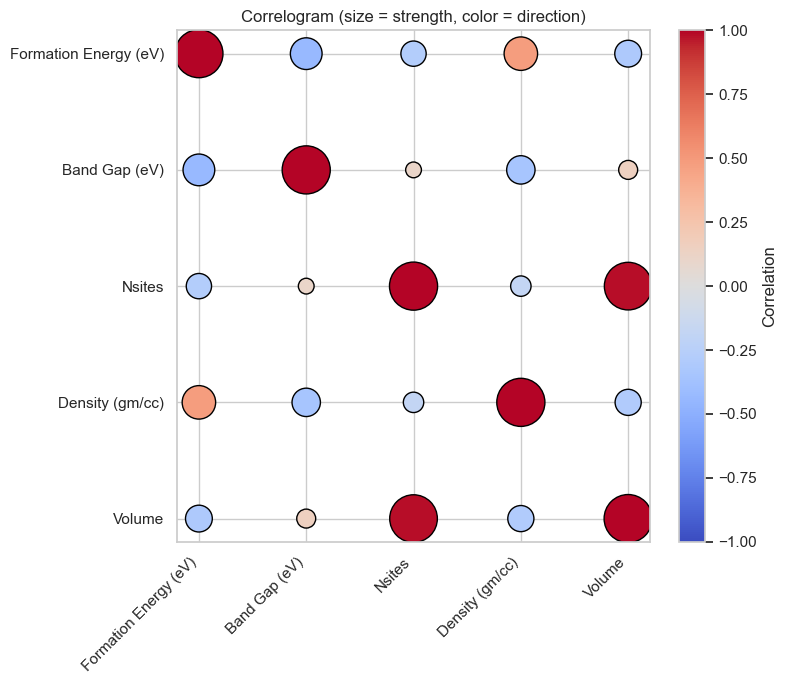

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url, na_values=["", "NA", "N/A"]).dropna()

num_cols = df.select_dtypes(include=np.number).columns.tolist()
for c in df.columns:
    if df[c].dtype == bool:
        df[c] = df[c].astype(str)
cat_small = [c for c in df.columns if c not in num_cols and 2 <= df[c].nunique() <= 8]
print("Numerical variables:", num_cols)
print("Categorical variables with few groups:", cat_small, "\n")

# Pick columns (falls back to automatic choice if a name is not in the data)
def pick(preferred, pool, used=()):
    for p in preferred:
        if p in pool and p not in used:
            return p
    return next(c for c in pool if c not in used)

cat1 = pick(["Crystal System"], cat_small)
cat2 = pick(["Has Bandstructure"], cat_small, [cat1])
x = pick(["Density (gm/cc)"], num_cols)
y = pick(["Formation Energy (eV)"], num_cols, [x])
z = pick(["Band Gap (eV)"], num_cols, [x, y])
line_x = pick(["Nsites"], num_cols, [y])
print("Categories:", cat1, "&", cat2, "| Numerics:", x, ",", y, ",", z, "\n")

# 2. Contingency table and stacked bar plots
ct = pd.crosstab(df[cat1], df[cat2])
print("Contingency table:\n", ct, "\n")

# 2a. Simple stacked bar plot (matplotlib, like Base R barplot)
bottom = np.zeros(len(ct))
plt.figure(figsize=(8, 5))
for col in ct.columns:
    plt.bar(ct.index, ct[col], bottom=bottom, label=str(col), edgecolor="black")
    bottom += ct[col].values
plt.title(f"Stacked Bar Plot: {cat1} by {cat2} (Base style)")
plt.xlabel(cat1); plt.ylabel("Count"); plt.xticks(rotation=30)
plt.legend(title=cat2); plt.tight_layout(); plt.show()

# 2b. Stacked bar plot (seaborn/ggplot2 style)
sns.set_theme(style="whitegrid")
ct.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2", edgecolor="black")
plt.title(f"Stacked Bar Plot: {cat1} by {cat2} (ggplot2 style)")
plt.xlabel(cat1); plt.ylabel("Count"); plt.xticks(rotation=30)
plt.legend(title=cat2); plt.tight_layout(); plt.show()

# 3. Grouped (side-by-side) bar plot
ct.plot(kind="bar", figsize=(8, 5), colormap="Set1", edgecolor="black")
plt.title(f"Grouped Bar Plot: {cat1} and {cat2}")
plt.xlabel(cat1); plt.ylabel("Frequency"); plt.xticks(rotation=30)
plt.legend(title=cat2); plt.tight_layout(); plt.show()

# 4. Scatter plot of two numerical variables
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=x, y=y, alpha=0.6, color="steelblue")
plt.title(f"Scatter Plot: {y} vs {x}")
plt.xlabel(x); plt.ylabel(y); plt.tight_layout(); plt.show()

# 5. Line plot (average of y for each value of line_x)
trend = df.groupby(line_x)[y].mean().reset_index()
plt.figure(figsize=(8, 5))
plt.plot(trend[line_x], trend[y], marker="o", color="darkgreen")
plt.title(f"Line Plot: Average {y} by {line_x}")
plt.xlabel(line_x); plt.ylabel("Average " + y); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 6. Heatmap of numerical variables
corr_cols = num_cols[:8]
corr = df[corr_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Heatmap of Numerical Variables")
plt.tight_layout(); plt.show()

# 7. Bar chart comparing two variables across categories (mean values)
means = df.groupby(cat1)[[y, z]].mean()
means.plot(kind="bar", figsize=(8, 5), edgecolor="black", colormap="tab10")
plt.title(f"Average {y} and {z} by {cat1}")
plt.xlabel(cat1); plt.ylabel("Average value"); plt.xticks(rotation=30)
plt.legend(title="Variable"); plt.tight_layout(); plt.show()

# 8. Density plot (numerical variable across categories)
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x=y, hue=cat1, fill=True, alpha=0.3, common_norm=False)
plt.title(f"Density Plot of {y} by {cat1}")
plt.xlabel(y); plt.ylabel("Density"); plt.tight_layout(); plt.show()

# 9. Box plot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=cat1, y=y, palette="Set2")
plt.title(f"Box Plot of {y} by {cat1}")
plt.xlabel(cat1); plt.ylabel(y); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# 10. Violin plot
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x=cat1, y=y, palette="Set3")
plt.title(f"Violin Plot of {y} by {cat1}")
plt.xlabel(cat1); plt.ylabel(y); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# 11. Violin plot combined with box plot
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x=cat1, y=y, palette="pastel", inner=None)
sns.boxplot(data=df, x=cat1, y=y, width=0.15, color="white", boxprops={"zorder": 2})
plt.title(f"Violin + Box Plot of {y} by {cat1}")
plt.xlabel(cat1); plt.ylabel(y); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# 12. Correlation matrix and correlogram (circle size = strength, color = direction)
print("Correlation matrix:\n", corr.round(2), "\n")
n = len(corr_cols)
gx, gy = np.meshgrid(range(n), range(n))
plt.figure(figsize=(8, 7))
sc = plt.scatter(gx.ravel(), gy.ravel(), s=np.abs(corr.values.ravel()) * 1200,
                 c=corr.values.ravel(), cmap="coolwarm", vmin=-1, vmax=1, edgecolor="black")
plt.xticks(range(n), corr_cols, rotation=45, ha="right"); plt.yticks(range(n), corr_cols)
plt.gca().invert_yaxis(); plt.colorbar(sc, label="Correlation")
plt.title("Correlogram (size = strength, color = direction)")
plt.tight_layout(); plt.show()

# 13. All plots above already include titles, axis labels, legends and graphical settings

In [ ]:
#Lab Assessment 5 - 

Multivariate Analysis

We load the lithium-ion dataset, separate the numerical and categorical variables, and draw 
scatter plots that add a third and fourth variable using color, shape and point size, followed 
by a bubble plot. Facet wrap and facet grid split the same scatter plot into subplots by Crystal
System and Has Bandstructure, so patterns can be compared across groups. The pairs plot with its
correlation matrix shows relationships between four numerical variables, and the parallel 
coordinate plot compares them across crystal systems.

Numerical variables: ['Formation Energy (eV)', 'Band Gap (eV)', 'Nsites', 'Density (gm/cc)', 'Volume']
Categorical variables: ['Materials Id', 'Formula', 'Spacegroup', 'E Above Hull (eV)', 'Has Bandstructure', 'Crystal System'] 

Categorical columns with few groups: ['Has Bandstructure', 'Crystal System'] 

X: Density (gm/cc) | Y: Formation Energy (eV) | Size/third numeric: Volume | Fourth numeric: Nsites
Category 1: Crystal System | Category 2: Has Bandstructure 



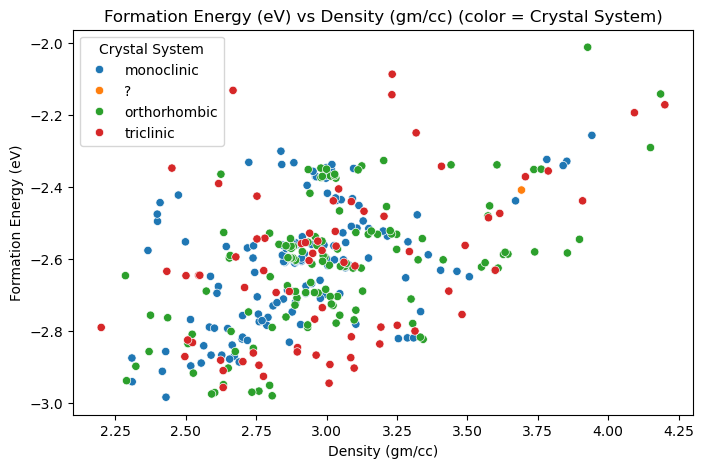

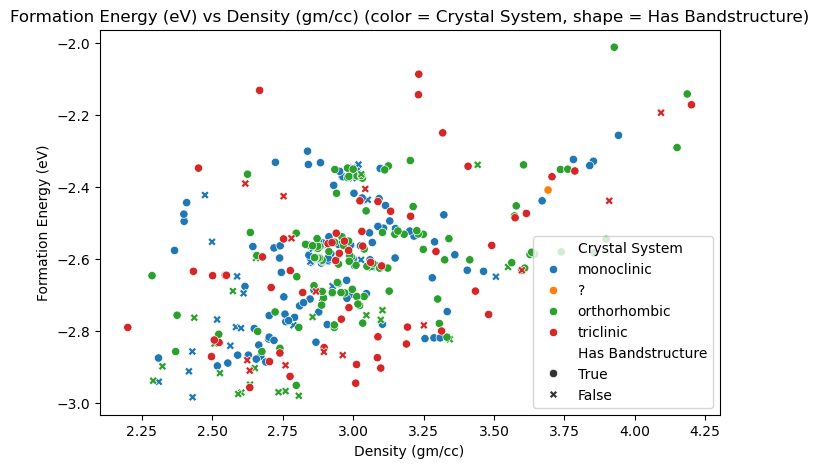

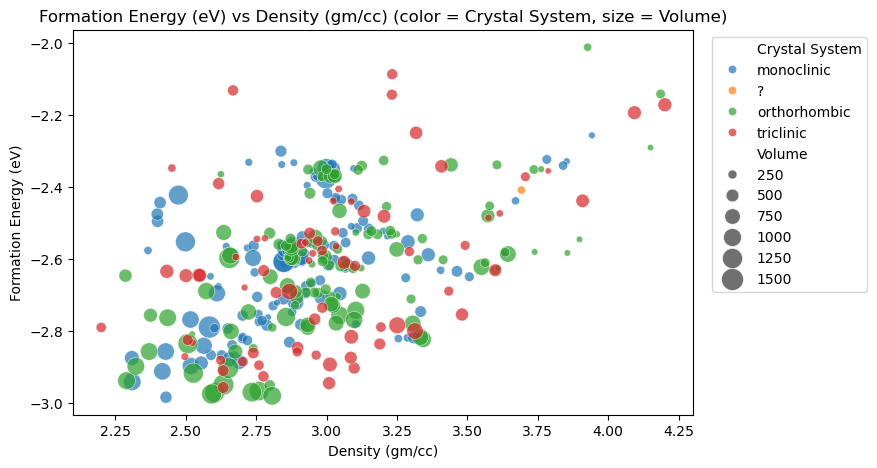

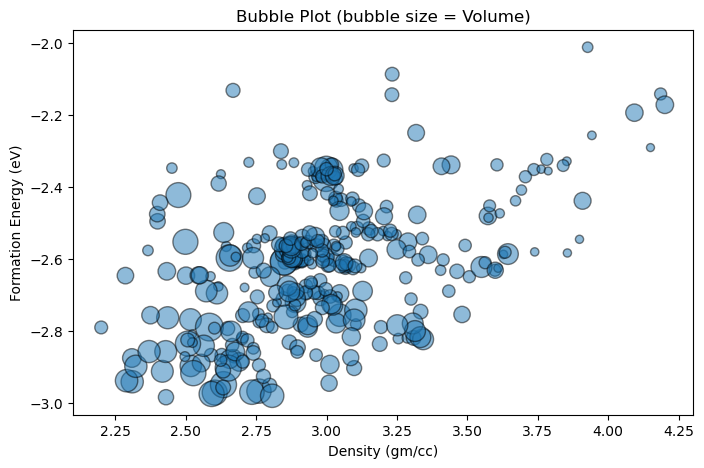

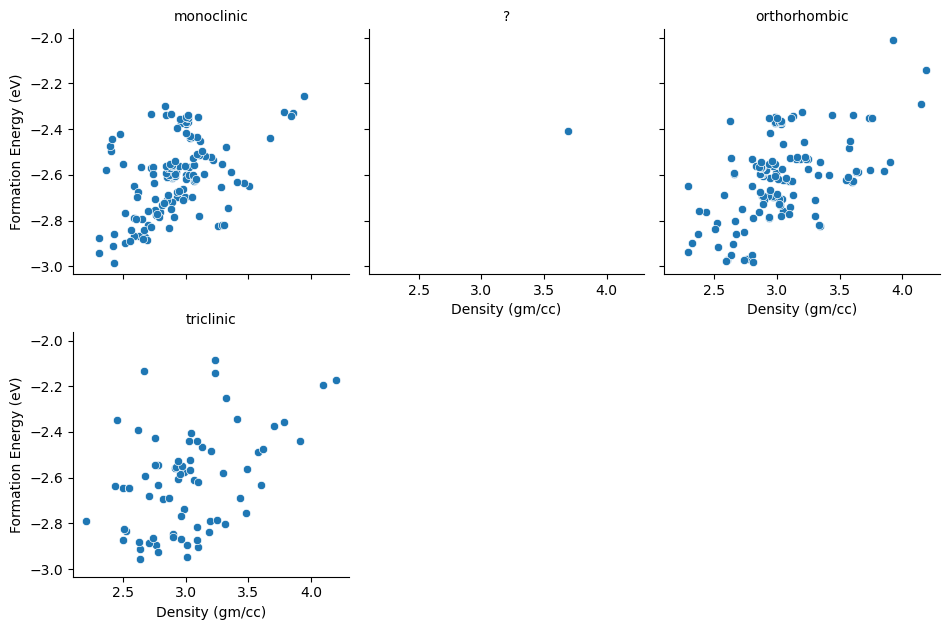

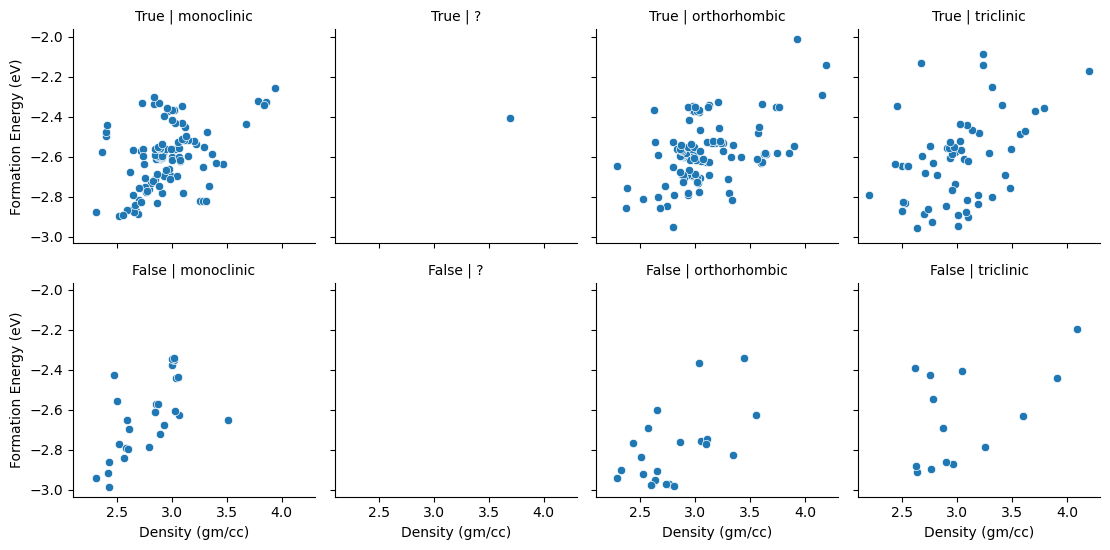

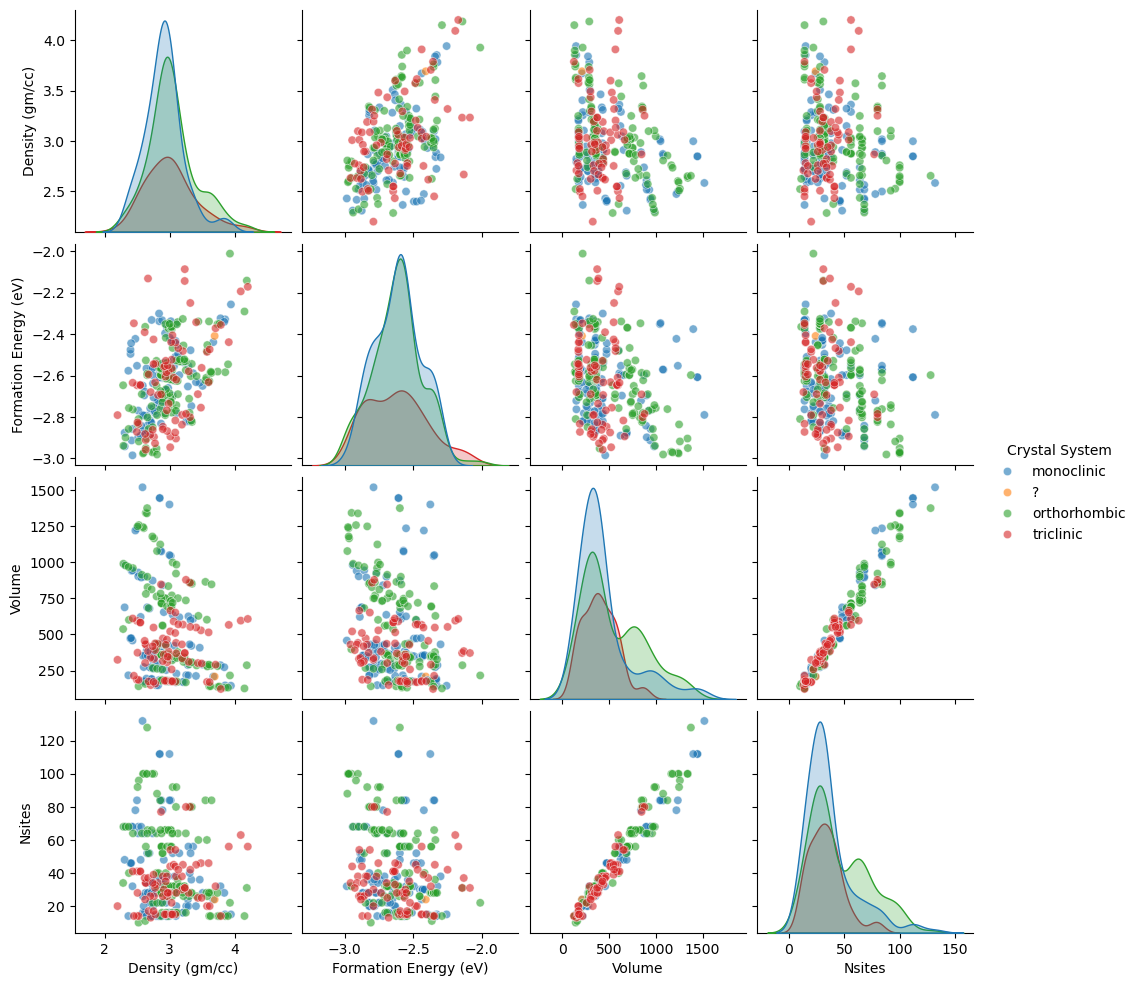

Correlation matrix:
                        Density (gm/cc)  Formation Energy (eV)  Volume  Nsites
Density (gm/cc)                   1.00                   0.48   -0.29   -0.18
Formation Energy (eV)             0.48                   1.00   -0.31   -0.28
Volume                           -0.29                  -0.31    1.00    0.98
Nsites                           -0.18                  -0.28    0.98    1.00 



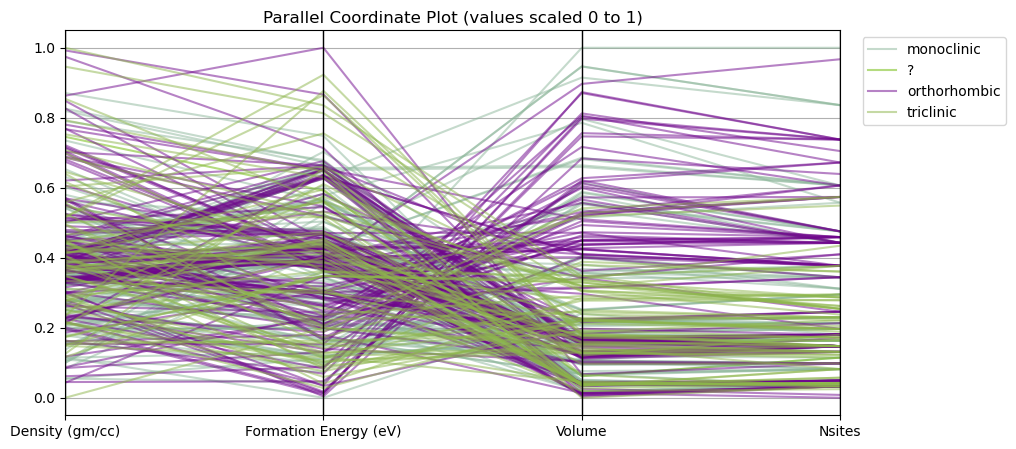

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import parallel_coordinates

# 1. Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url, na_values=["", "NA", "N/A"])
df = df.dropna()

# Identify numerical and categorical variables
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_all = [c for c in df.columns if c not in num_cols]
print("Numerical variables:", num_cols)
print("Categorical variables:", cat_all, "\n")

# Categorical columns with few groups (suitable for color, shape and facets)
for c in cat_all:
    if df[c].dtype == bool:
        df[c] = df[c].astype(str)
cat_small = [c for c in cat_all if 2 <= df[c].nunique() <= 8]
print("Categorical columns with few groups:", cat_small, "\n")

# Pick columns (falls back to automatic choice if a name is not in the data)
def pick(preferred, pool, used=()):
    for p in preferred:
        if p in pool and p not in used:
            return p
    return next(c for c in pool if c not in used)

x = pick(["Density (gm/cc)"], num_cols)
y = pick(["Formation Energy (eV)"], num_cols, [x])
z = pick(["Volume"], num_cols, [x, y])
w = pick(["Nsites", "Band Gap (eV)"], num_cols, [x, y, z])
cat1 = pick(["Crystal System"], cat_small)
cat2 = pick(["Has Bandstructure"], cat_small, [cat1])
print("X:", x, "| Y:", y, "| Size/third numeric:", z, "| Fourth numeric:", w)
print("Category 1:", cat1, "| Category 2:", cat2, "\n")

# 2. Scatter plot with three variables (X, Y, color)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=x, y=y, hue=cat1)
plt.title(f"{y} vs {x} (color = {cat1})"); plt.show()

# 3. Scatter plot with four variables (X, Y, color, shape)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=x, y=y, hue=cat1, style=cat2)
plt.title(f"{y} vs {x} (color = {cat1}, shape = {cat2})"); plt.show()

# 4. Scatter plot with four variables (X, Y, color, size)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=x, y=y, hue=cat1, size=z, sizes=(20, 250), alpha=0.7)
plt.title(f"{y} vs {x} (color = {cat1}, size = {z})")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

# 5. Bubble plot (three numerical variables)
plt.figure(figsize=(8, 5))
plt.scatter(df[x], df[y], s=(df[z] / df[z].max()) * 400, alpha=0.5, edgecolor="black")
plt.xlabel(x); plt.ylabel(y); plt.title(f"Bubble Plot (bubble size = {z})"); plt.show()

# 6. Facet wrap (subplots by one categorical variable)
g = sns.relplot(data=df, x=x, y=y, col=cat1, col_wrap=3, height=3.2, kind="scatter")
g.set_titles("{col_name}"); plt.show()

# 7. Facet grid (rows and columns by two categorical variables)
g = sns.relplot(data=df, x=x, y=y, row=cat2, col=cat1, height=2.8, kind="scatter")
g.set_titles("{row_name} | {col_name}"); plt.show()

# 8. Pairs plot (four numerical variables) and correlations
pair_cols = [x, y, z, w]
sns.pairplot(df[pair_cols + [cat1]], hue=cat1, corner=False, plot_kws={"alpha": 0.6})
plt.show()
print("Correlation matrix:\n", df[pair_cols].corr().round(2), "\n")

# 9. Parallel coordinate plot (normalised numerical variables, colored by category)
pc = df[pair_cols].copy()
pc = (pc - pc.min()) / (pc.max() - pc.min())
pc[cat1] = df[cat1].values
plt.figure(figsize=(10, 5))
parallel_coordinates(pc, cat1, alpha=0.5)
plt.title("Parallel Coordinate Plot (values scaled 0 to 1)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

In [ ]:
#Assessment 6

Time Series Analysis

We load the monthly AirPassengers data (1949 to 1960), check its start, end and frequency (12), 
and plot it to see a rising trend with yearly seasonality. We then decompose it into trend, 
seasonal and random parts, study ACF/PACF, fit a seasonal ARIMA(0,1,1)(0,1,1)12 model on the 
log of the data, and forecast the next 12 months, plotting the forecast against the actual 
values.

First 5:
 1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64 

Last 5:
 1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64 

Start: Jan 1949 | End: Dec 1960 

Frequency (observations per year): 12
Index type: DatetimeIndex | Series type: Series
Length: 144 | Min: 104 | Max: 622 



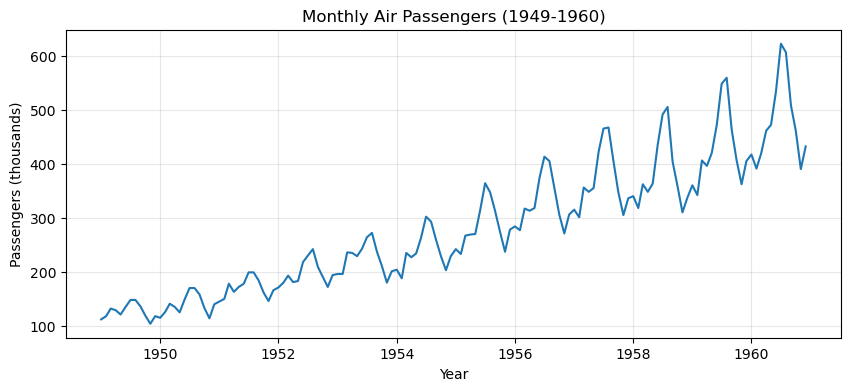

Seasonal pattern (one year):
 1949-01-01   -24.75
1949-02-01   -36.19
1949-03-01    -2.24
1949-04-01    -8.04
1949-05-01    -4.51
1949-06-01    35.40
1949-07-01    63.83
1949-08-01    62.82
1949-09-01    16.52
1949-10-01   -20.64
1949-11-01   -53.59
1949-12-01   -28.62
Freq: MS, Name: seasonal, dtype: float64 



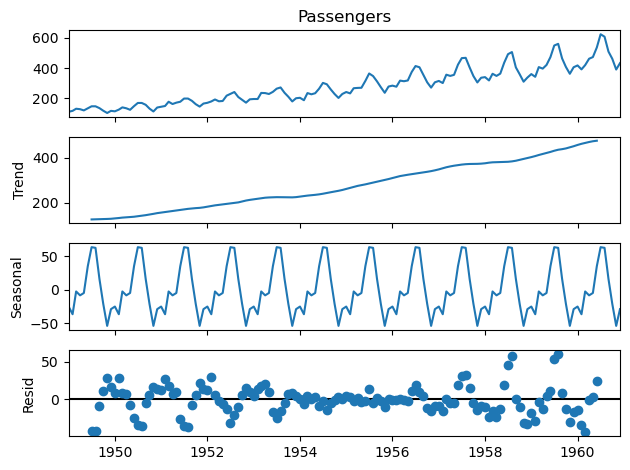

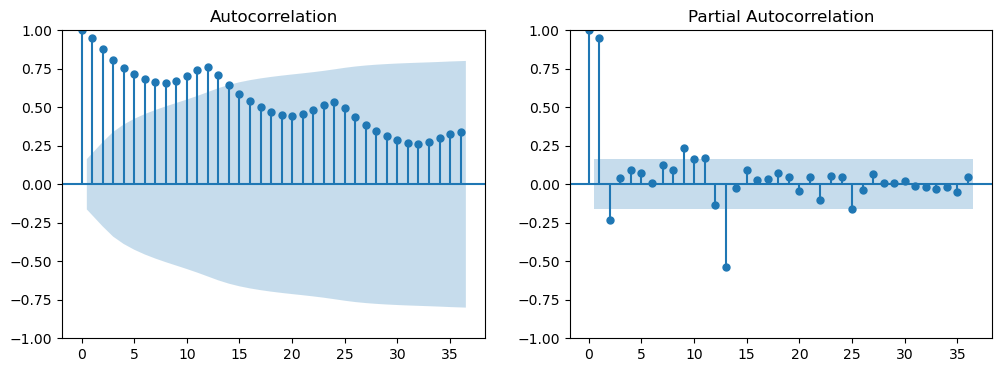

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                            Thu, 15 Oct 2026   AIC                           -483.393
Time:                                    19:26:51   BIC                           -474.767
Sample:                                01-01-1949   HQIC                          -479.888
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4015      0.073     -5.500      0.000      -0.545      -0.258
ma.S.L12      -0.5562      0.096   

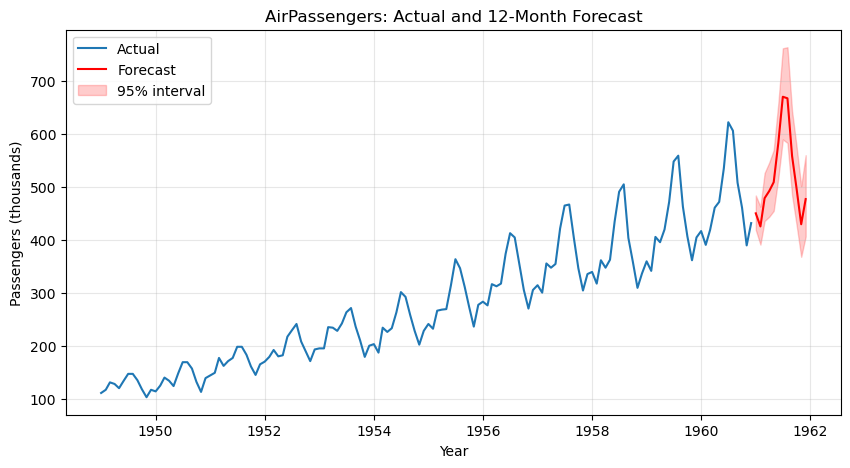

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Load the AirPassengers dataset (monthly passengers in thousands, Jan 1949 to Dec 1960)
values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432]
ts = pd.Series(values, index=pd.date_range("1949-01", periods=144, freq="MS"), name="Passengers")

# 2. First five and last five observations
print("First 5:\n", ts.head(5), "\n")
print("Last 5:\n", ts.tail(5), "\n")

# 3. Start and end of the time series
print("Start:", ts.index[0].strftime("%b %Y"), "| End:", ts.index[-1].strftime("%b %Y"), "\n")

# 4. Frequency and time-series characteristics
print("Frequency (observations per year):", 12)
print("Index type:", type(ts.index).__name__, "| Series type:", type(ts).__name__)
print("Length:", len(ts), "| Min:", ts.min(), "| Max:", ts.max(), "\n")

# 5. Monthly passenger trend
plt.figure(figsize=(10, 4))
plt.plot(ts)
plt.title("Monthly Air Passengers (1949-1960)")
plt.xlabel("Year"); plt.ylabel("Passengers (thousands)"); plt.grid(alpha=0.3); plt.show()

# 6. Decompose into trend, seasonal and random components
decomp = seasonal_decompose(ts, model="additive", period=12)
print("Seasonal pattern (one year):\n", decomp.seasonal.head(12).round(2), "\n")

# 7. Plot the decomposed components
decomp.plot()
plt.show()

# 8. Autocorrelation and partial autocorrelation
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ts, lags=36, ax=ax[0])
plot_pacf(ts, lags=36, ax=ax[1], method="ywm")
plt.show()

# 9. Fit an ARIMA model (log transform, ARIMA(0,1,1)(0,1,1)12)
log_ts = np.log(ts)
model = SARIMAX(log_ts, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
fit = model.fit(disp=False)

# 10. Model parameters and summary
print(fit.summary(), "\n")
print("AIC:", round(fit.aic, 2), "| BIC:", round(fit.bic, 2), "\n")

# 11. Forecast the next 12 months
pred = fit.get_forecast(steps=12)
forecast = np.exp(pred.predicted_mean)
conf = np.exp(pred.conf_int())
print("Forecast for next 12 months:\n", forecast.round(0), "\n")

# 12. Actual vs forecasted values
plt.figure(figsize=(10, 5))
plt.plot(ts, label="Actual")
plt.plot(forecast, color="red", label="Forecast")
plt.fill_between(conf.index, conf.iloc[:, 0], conf.iloc[:, 1], color="red", alpha=0.2, label="95% interval")
plt.title("AirPassengers: Actual and 12-Month Forecast")
plt.xlabel("Year"); plt.ylabel("Passengers (thousands)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
#Assessment 7

1 D, 2 D and N D Analysis

This Python program performs Exploratory Data Analysis (EDA) on the Lithium-ion Batteries 
dataset. It calculates summary statistics and creates frequency distribution tables, pie charts,
bar plots, histograms, and box plots. It uses cross-tabulation to analyze categorical variables 
and calculates grouped statistics for numerical data. It also computes Pearson and Spearman 
correlations, creates scatter plots with regression lines, generates correlation heatmaps, 
and produces pairs plots to understand relationships, distributions, and outliers in the dataset.

  Materials Id       Formula Spacegroup  Formation Energy (eV)  \
0    mp-849394     Li2MnSiO4         Pc                 -2.699   
1    mp-783909     Li2MnSiO4      P21/c                 -2.696   
2    mp-761311    Li4MnSi2O7         Cc                 -2.775   
3    mp-761598  Li4Mn2Si3O10       C2/c                 -2.783   
4    mp-767709  Li2Mn3Si3O10       C2/c                 -2.747   

  E Above Hull (eV)  Band Gap (eV)  Nsites  Density (gm/cc)   Volume  \
0             0.006          3.462      16            2.993  178.513   
1             0.008          2.879      32            2.926  365.272   
2             0.012          3.653      28            2.761  301.775   
3             0.013          3.015      38            2.908  436.183   
4             0.016          2.578      36            3.334  421.286   

   Has Bandstructure Crystal System  
0               True     monoclinic  
1               True     monoclinic  
2               True     monoclinic  
3               Tr

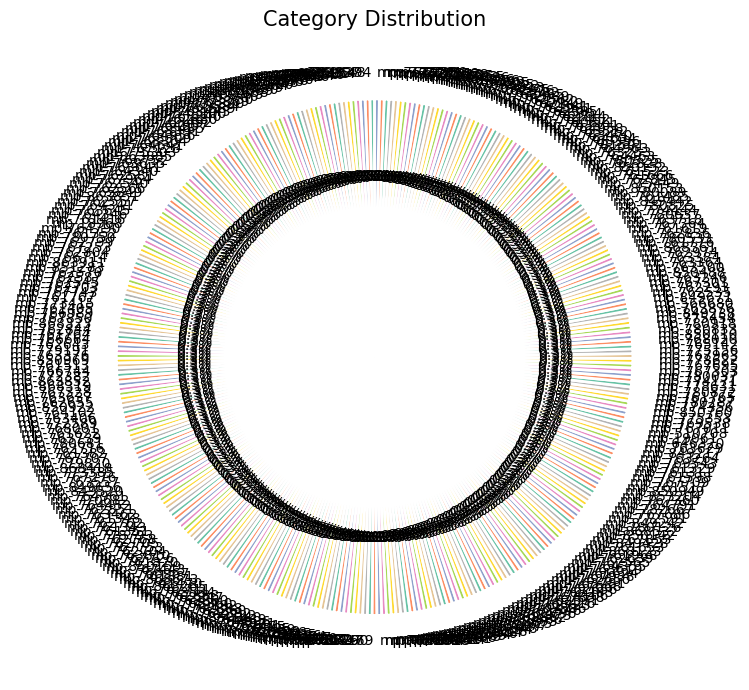

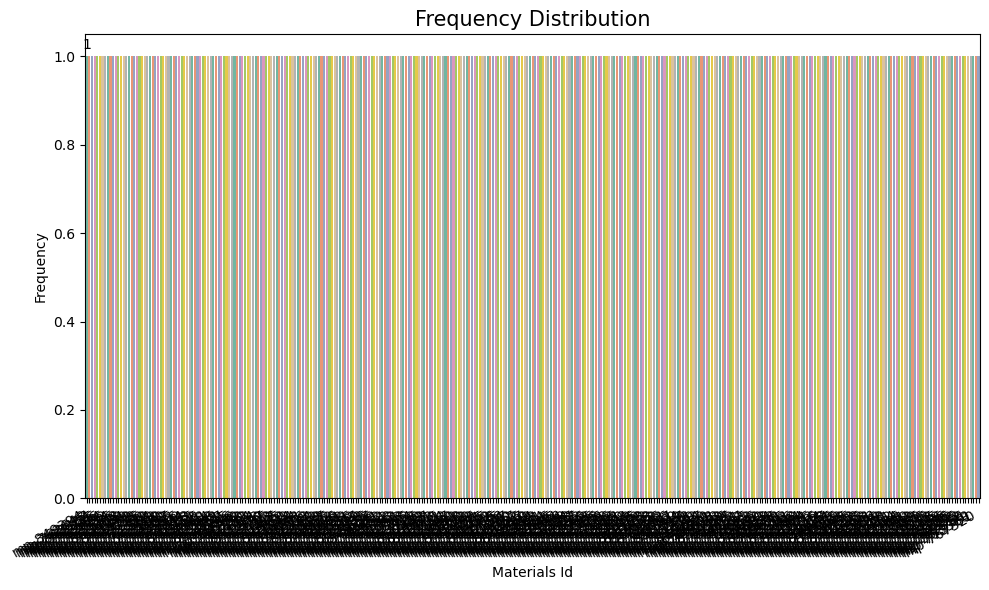

Numerical Frequency:
 Formation Energy (eV)
(-2.986, -2.823]     52
(-2.823, -2.661]     77
(-2.661, -2.498]    132
(-2.498, -2.336]     62
(-2.336, -2.174]     10
(-2.174, -2.012]      6
Name: count, dtype: int64


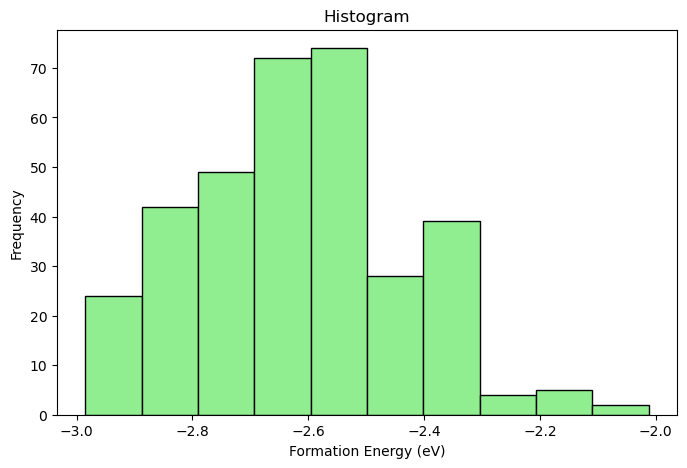

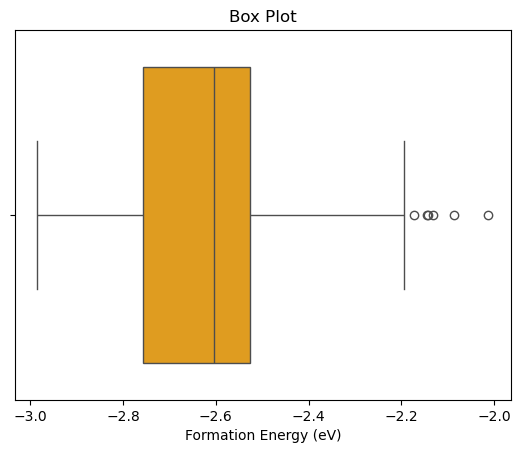

Contingency Table:
 Formula       Li10Co(SiO5)2  Li10Fe(SiO5)2  Li10Mn(SiO5)2  Li15Mn15SiO32  \
Materials Id                                                               
mp-18968                  0              0              0              0   
mp-19061                  0              0              0              0   
mp-510708                 0              0              0              0   
mp-543100                 0              0              0              0   
mp-566680                 0              0              0              0   
...                     ...            ...            ...            ...   
mp-868418                 0              0              0              0   
mp-868526                 0              0              0              0   
mp-868532                 0              0              0              0   
mp-868566                 0              0              0              0   
mp-868673                 0              0              0           

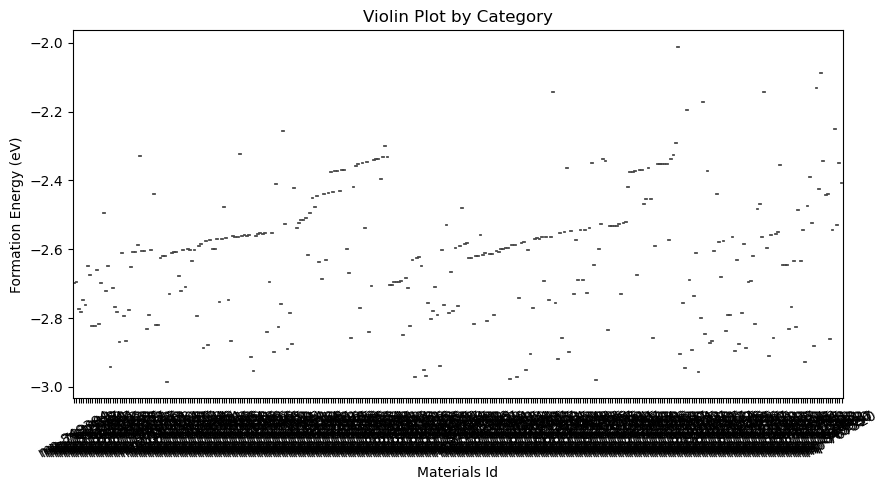

Pearson Correlation: -0.43817797458090335
Spearman Correlation: -0.49050890856532


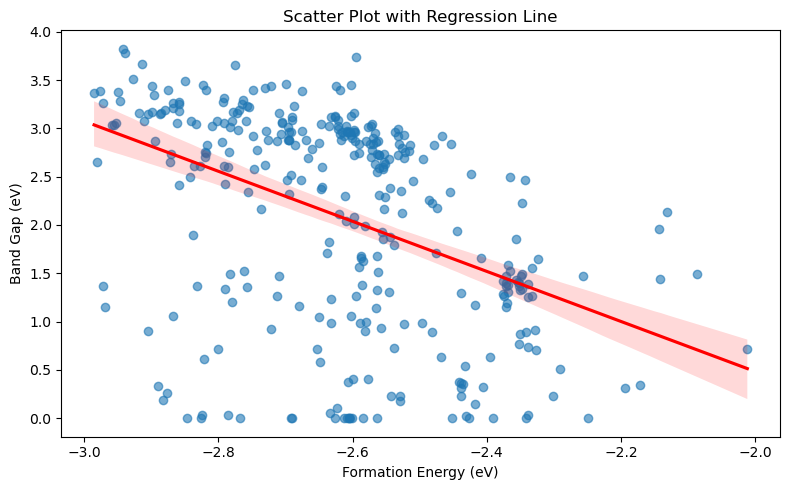

Combined Statistics:
     Materials Id        Formula   Mean  SD
0       mp-18968      Li2FeSiO4 -2.626 NaN
1       mp-19061    LiFe(SiO3)2 -2.820 NaN
2      mp-510708    LiFe(SiO3)2 -2.820 NaN
3      mp-543100       LiCoSiO4 -2.371 NaN
4      mp-566680      Li2MnSiO4 -2.705 NaN
..           ...            ...    ...  ..
333    mp-868418     Li2FeSi3O8 -2.826 NaN
334    mp-868526  Li9Mn5(SiO8)2 -2.372 NaN
335    mp-868532   Li5Mn(SiO4)2 -2.649 NaN
336    mp-868566    LiFe(SiO3)2 -2.790 NaN
337    mp-868673  Li15Mn15SiO32 -2.194 NaN

[338 rows x 4 columns]


In [ ]:
# 1. Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url)

print(df.head())
print(df.info())

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

num1, num2, num3 = num_cols[:3]
cat1, cat2 = cat_cols[:2]

# 2 & 3. Summary Statistics
x = df[num1].dropna()

stats = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range",
                  "Variance", "Standard Deviation", "IQR",
                  "Skewness", "Kurtosis"],
    "Value": [x.mean(), x.median(), x.min(), x.max(),
              x.max()-x.min(), x.var(), x.std(),
              x.quantile(0.75)-x.quantile(0.25),
              skew(x), kurtosis(x)]
})
print(stats)

# 4. Frequency Tables, Pie Chart and Bar Plot
freq = df[cat1].value_counts()
print("Frequency:\n", freq)
print("Relative Frequency:\n", df[cat1].value_counts(normalize=True))

colors = sns.color_palette("Set2", len(freq))

plt.figure(figsize=(9, 7))
plt.pie(freq, labels=freq.index, autopct="%1.1f%%",
        startangle=90, colors=colors, pctdistance=0.7,
        wedgeprops={"edgecolor": "white", "linewidth": 2})
plt.title("Category Distribution", fontsize=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=freq.index, y=freq.values,
                 hue=freq.index, palette="Set2", legend=False)
ax.bar_label(ax.containers[0], padding=3)
plt.title("Frequency Distribution", fontsize=15)
plt.xlabel(cat1)
plt.ylabel("Frequency")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 5. Numerical Frequency, Histogram and Box Plot
y = df[num1].dropna()
bins = pd.cut(y, bins=6)
print("Numerical Frequency:\n", bins.value_counts().sort_index())

plt.figure(figsize=(8, 5))
plt.hist(y, bins=10, color="lightgreen", edgecolor="black")
plt.title("Histogram")
plt.xlabel(num1)
plt.ylabel("Frequency")
plt.show()

sns.boxplot(x=y, color="orange")
plt.title("Box Plot")
plt.show()

# 6. Contingency Table and Percentages
tab = pd.crosstab(df[cat1], df[cat2])
print("Contingency Table:\n", tab)
print("Row Percentages:\n", tab.div(tab.sum(axis=1), axis=0)*100)
print("Column Percentages:\n", tab.div(tab.sum(axis=0), axis=1)*100)

# 7. Stacked and Grouped Bar Plots
tab.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="Set2")
plt.title("Stacked Bar Plot")
plt.tight_layout()
plt.show()

tab.plot(kind="bar", figsize=(9, 5), colormap="Set2")
plt.title("Grouped Bar Plot")
plt.tight_layout()
plt.show()

# 8. Grouped Statistics
group_stats = df.groupby(cat1)[num1].agg(
    ["mean", "median", "std"])
print("Grouped Statistics:\n", group_stats)

# 9. Box Plot and Violin Plot
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x=cat1, y=num1)
plt.xticks(rotation=30)
plt.title("Box Plot by Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x=cat1, y=num1)
plt.xticks(rotation=30)
plt.title("Violin Plot by Category")
plt.tight_layout()
plt.show()

# 10. Correlation and Scatter Plot
print("Pearson Correlation:", df[num1].corr(df[num2], method="pearson"))
print("Spearman Correlation:", df[num1].corr(df[num2], method="spearman"))

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x=num1, y=num2,
            scatter_kws={"alpha": 0.6},
            line_kws={"color": "red"})
plt.title("Scatter Plot with Regression Line")
plt.tight_layout()
plt.show()

# 11. Two Categories and One Numerical Variable
combo = df.groupby([cat1, cat2])[num1].agg(
    Mean="mean", SD="std").reset_index()
print("Combined Statistics:\n", combo)

sns.catplot(data=df, x=cat1, y=num1, col=cat2,
            kind="box", height=4, aspect=1)
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x=cat1, y=num1, hue=cat2,
            errorbar="sd", palette="Set2")
plt.title("Grouped Means with SD Error Bars")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 12. Category-Wise Scatter Plot and Correlation
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=num1, y=num2,
                hue=cat1, style=cat1)
plt.title("Scatter Plot by Category")
plt.tight_layout()
plt.show()

for category, group in df.groupby(cat1, observed=True):
    print("\nCategory:", category)
    print(group[[num1, num2]].corr())

# 13. Correlation Matrix and Heatmap
numeric_data = df[num_cols]
valid = numeric_data.columns[
    (numeric_data.notna().sum() >= 2) &
    (numeric_data.std() > 0)
]
numeric_data = numeric_data[valid]
corr = numeric_data.corr()
print("Correlation Matrix:\n", corr)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 14. Pairs Plot
sns.pairplot(df[num_cols], diag_kind="hist")
plt.show()

In [ ]:
#Assessment 8: 

K-Means Clustering,Hierarchical Clustering

We load the lithium-ion dataset, check for missing values, keep only the numerical columns and 
standardize them so every feature has equal weight. For K-Means we cluster with K=2, print the 
results and centers, compute WCSS for K=1 to 10, plot the elbow curve and re-run K-Means with 
the K the elbow suggests. For hierarchical clustering we compute Euclidean distances, link the 
data using Ward’s method, plot the dendrogram, cut it into 3 clusters and count the samples in 
each.

  Materials Id       Formula Spacegroup  Formation Energy (eV)  \
0    mp-849394     Li2MnSiO4         Pc                 -2.699   
1    mp-783909     Li2MnSiO4      P21/c                 -2.696   
2    mp-761311    Li4MnSi2O7         Cc                 -2.775   
3    mp-761598  Li4Mn2Si3O10       C2/c                 -2.783   
4    mp-767709  Li2Mn3Si3O10       C2/c                 -2.747   
5    mp-761517    Li4MnSi2O7         C2                 -2.763   
6    mp-850949      LiMnSiO4        P21                 -2.650   
7    mp-853204     Li2MnSiO4      P21/c                 -2.676   
8    mp-767360   LiMn(SiO3)2       C2/c                 -2.822   
9    mp-764791  Li2Mn(SiO3)2         Cc                 -2.823   

  E Above Hull (eV)  Band Gap (eV)  Nsites  Density (gm/cc)   Volume  \
0             0.006          3.462      16            2.993  178.513   
1             0.008          2.879      32            2.926  365.272   
2             0.012          3.653      28            2.7

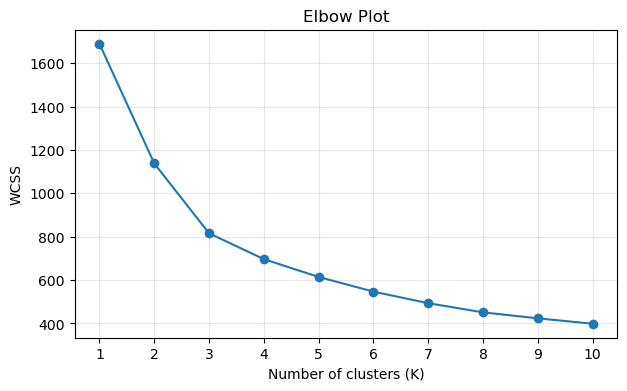

C:\Users\alekh\AppData\Local\Temp\ipykernel_6772\2760554423.py:58: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  dist_line = [abs(np.cross(p2 - p1, p1 - np.array([k, w]))) / np.linalg.norm(p2 - p1) for k, w in zip(ks, wcss)]


Elbow recommends K = 3
Cluster sizes (K = 3 ):
 0    110
1    154
2     74
Name: count, dtype: int64 

Cluster centers:
    Formation Energy (eV)  Band Gap (eV)  Nsites  Density (gm/cc)  Volume
0                  0.875         -1.053  -0.450            0.689  -0.491
1                 -0.329          0.586  -0.437           -0.262  -0.422
2                 -0.617          0.347   1.578           -0.478   1.608 

  Materials Id       Formula Spacegroup  Formation Energy (eV)  \
0    mp-849394     Li2MnSiO4         Pc                 -2.699   
1    mp-783909     Li2MnSiO4      P21/c                 -2.696   
2    mp-761311    Li4MnSi2O7         Cc                 -2.775   
3    mp-761598  Li4Mn2Si3O10       C2/c                 -2.783   
4    mp-767709  Li2Mn3Si3O10       C2/c                 -2.747   
5    mp-761517    Li4MnSi2O7         C2                 -2.763   
6    mp-850949      LiMnSiO4        P21                 -2.650   
7    mp-853204     Li2MnSiO4      P21/c                 -

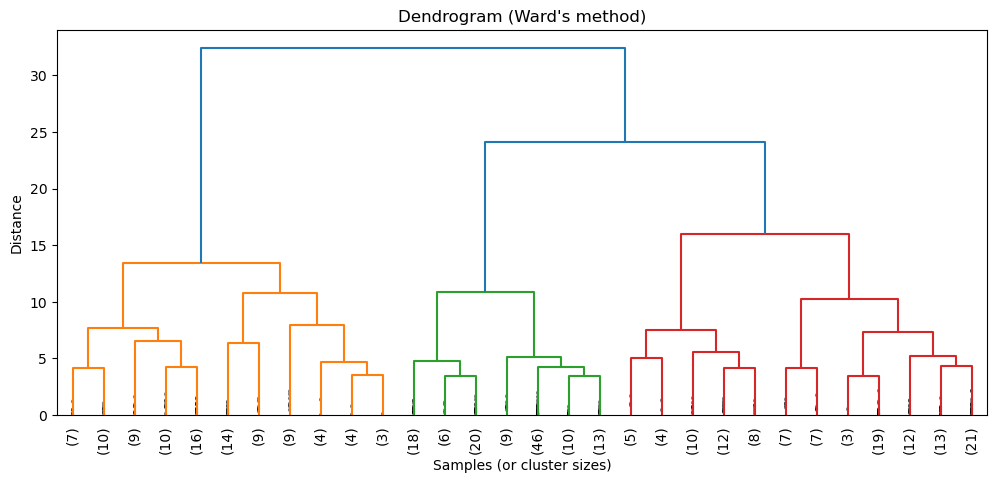

First 20 cluster assignments: [2 2 2 2 2 2 3 2 3 2 2 2 1 1 1 3 1 3 1 3] 

Samples in each cluster:
 1     95
2    122
3    121
Name: count, dtype: int64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

# ==================== K-MEANS CLUSTERING ====================

# 1. Load the dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url, na_values=["", "NA", "N/A"])

# 2. View the dataset
print(df.head(10), "\n")
print("Shape:", df.shape, "\n")

# 3. Check missing values
print("Missing values per column:\n", df.isnull().sum(), "\n")

# 4. Distribution of the dependent (categorical) variable
target = "Crystal System" if "Crystal System" in df.columns else df.select_dtypes(exclude=np.number).columns[0]
print("Distribution of", target, ":\n", df[target].value_counts(), "\n")

# 5. Select only numerical features (remove the rest)
num_df = df.select_dtypes(include=np.number).dropna()
print("Numerical features used:", list(num_df.columns), "\n")

# 6. Standardize the data
scaled = StandardScaler().fit_transform(num_df)

# 7. Apply K-Means with 2 centers
km2 = KMeans(n_clusters=2, n_init=25, random_state=42).fit(scaled)

# 8. Display K-Means results
print("Cluster sizes (K=2):\n", pd.Series(km2.labels_).value_counts().sort_index(), "\n")
print("First 10 cluster labels:", km2.labels_[:10], "")
print("WCSS (K=2):", round(km2.inertia_, 2), "\n")

# 9. Display cluster centers
print("Cluster centers (standardized):\n",
      pd.DataFrame(km2.cluster_centers_, columns=num_df.columns).round(3), "\n")

# 10. WCSS for K = 1 to 10
ks = range(1, 11)
wcss = [KMeans(n_clusters=k, n_init=25, random_state=42).fit(scaled).inertia_ for k in ks]
print("WCSS for K = 1 to 10:\n", pd.DataFrame({"K": list(ks), "WCSS": np.round(wcss, 2)}), "\n")

# 11. Elbow plot
plt.figure(figsize=(7, 4))
plt.plot(ks, wcss, marker="o")
plt.title("Elbow Plot"); plt.xlabel("Number of clusters (K)"); plt.ylabel("WCSS")
plt.xticks(list(ks)); plt.grid(alpha=0.3); plt.show()

# 12. K-Means based on the elbow recommendation (point farthest from the line joining first and last WCSS)
p1, p2 = np.array([1, wcss[0]]), np.array([10, wcss[-1]])
dist_line = [abs(np.cross(p2 - p1, p1 - np.array([k, w]))) / np.linalg.norm(p2 - p1) for k, w in zip(ks, wcss)]
best_k = list(ks)[int(np.argmax(dist_line))]
print("Elbow recommends K =", best_k)
km_best = KMeans(n_clusters=best_k, n_init=25, random_state=42).fit(scaled)
print("Cluster sizes (K =", best_k, "):\n", pd.Series(km_best.labels_).value_counts().sort_index(), "\n")
print("Cluster centers:\n", pd.DataFrame(km_best.cluster_centers_, columns=num_df.columns).round(3), "\n")

# ==================== HIERARCHICAL CLUSTERING ====================

# 1-3. Load, view, check missing values (same dataset)
hdf = pd.read_csv(url, na_values=["", "NA", "N/A"])
print(hdf.head(10), "\n")
print("Missing values:", hdf.isnull().sum().sum(), "\n")

# 4. Select only numerical attributes
hnum = hdf.select_dtypes(include=np.number).dropna()

# 5. Standardize the data
hscaled = StandardScaler().fit_transform(hnum)

# 6. Euclidean distance
d = pdist(hscaled, metric="euclidean")
print("Number of pairwise distances:", len(d), "\n")

# 7. Hierarchical clustering using Ward's method
Z = linkage(hscaled, method="ward")   # Ward's method works on the standardized data (Euclidean)

# 8. Dendrogram
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
plt.title("Dendrogram (Ward's method)"); plt.xlabel("Samples (or cluster sizes)"); plt.ylabel("Distance")
plt.show()

# 9. Divide into 3 clusters and display assignments
clusters = fcluster(Z, t=3, criterion="maxclust")
print("First 20 cluster assignments:", clusters[:20], "\n")

# 10. Number of samples in each cluster
print("Samples in each cluster:\n", pd.Series(clusters).value_counts().sort_index())

In [ ]:
#Assessment - 9

Principal Component Analysis

We load the lithium-ion dataset, count its rows and columns, keep only the numeric columns,
remove missing values and standardize them into data_scaled. PCA is then applied, and its
summary shows the standard deviation and the proportion of variance explained by each component.
We plot a scree plot with labels, a biplot showing how the variables load on PC1 and PC2, store
the scores in pca_scores, and draw a PC1 vs PC2 scatter plot with your registration number in
the title.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load the dataset (matplotlib/sklearn replace ggplot2, ggfortify, FactoMineR, factoextra)
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/lithium-ion%20batteries.csv"
df = pd.read_csv(url, na_values=["", "NA", "N/A"])
print("Libraries loaded: pandas, numpy, matplotlib, scikit-learn\n")

# 2. Total rows and columns
print("Rows:", df.shape[0], " Columns:", df.shape[1], "\n")

# 3. Extract numeric columns, clean and normalize
num_df = df.select_dtypes(include=np.number).dropna()
data_scaled = pd.DataFrame(StandardScaler().fit_transform(num_df), columns=num_df.columns)
print("Numeric columns used:", list(num_df.columns))
print("Scaled data shape:", data_scaled.shape, "\n")

# 4. Perform PCA and print its summary
pca = PCA()
scores = pca.fit_transform(data_scaled)
pc_names = ["PC" + str(i + 1) for i in range(len(pca.explained_variance_))]
summary = pd.DataFrame({
    "Standard deviation": np.sqrt(pca.explained_variance_).round(4),
    "Proportion of variance": pca.explained_variance_ratio_.round(4),
    "Cumulative proportion": np.cumsum(pca.explained_variance_ratio_).round(4)
}, index=pc_names).T
print("PCA summary:\n", summary, "\n")

# 5. Scree plot with data labels (y-axis 0 to 60)
var_pct = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(8, 5))
plt.bar(pc_names, var_pct, color="steelblue", edgecolor="black")
plt.plot(pc_names, var_pct, "o-", color="red")
for i, v in enumerate(var_pct):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.ylim(0, 60)
plt.title("Scree Plot"); plt.xlabel("Principal Components"); plt.ylabel("Percentage of Variance Explained")
plt.show()

# 6. PCA biplot with non-overlapping labels
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scores[:, 0], scores[:, 1], alpha=0.3, color="gray", s=15)
scale = np.abs(scores[:, :2]).max()
texts = []
for i, col in enumerate(data_scaled.columns):
    x, y = pca.components_[0, i] * scale * 0.8, pca.components_[1, i] * scale * 0.8
    ax.arrow(0, 0, x, y, color="red", head_width=0.1, alpha=0.8)
    texts.append(ax.text(x, y, col, color="red", fontsize=9))
try:
    from adjustText import adjust_text   # pip install adjustText
    adjust_text(texts)
except ImportError:
    pass
ax.set_title("PCA Biplot (PC1 vs PC2)")
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}%)")
ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
plt.show()

# 7. PCA scores in a data frame
pca_scores = pd.DataFrame(scores, columns=pc_names)
print("First six rows of pca_scores:\n", pca_scores.head(6), "\n")

# 8. Scatter plot of PC1 vs PC2 (blue circular points, registration number in title)
reg_no = "23BDS0171"   # replace with your registration number
plt.figure(figsize=(7, 5))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", alpha=0.6)
plt.title(f"PC1 vs PC2 - {reg_no}")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.grid(alpha=0.3)
plt.show()